# Preparación de datos: química natural y sintética

Se muestran las observaciones disponibles para la próxima calibración: **LAB004–009 de mosto natural** y **MS007–016 de mosto sintético**. LAB010–012 quedan fuera de esta selección, conforme al alcance acordado. Los parámetros no se ajustan en este notebook.

Por cada variable se presenta primero la matriz de paneles naturales (2 × 3) y después la sintética (2 × 5), en este orden: **biomasa viable, YAN, glucosa, fructosa, glucosa + fructosa, densidad y etanol**. Cada marcador es una observación disponible; los segmentos unen puntos en orden temporal y no son simulaciones ni muestras interpoladas. `n` indica los puntos realmente dibujados. Las escalas verticales de una misma variable son comunes a ambas matrices; el tiempo comparte escala dentro de cada matriz y conserva su referencia histórica.

La biomasa viable es la usada por el estado X (30 pg/célula; g/L = kg/m³); YAN se muestra en mg N/L, azúcares y etanol en g/L, y densidad en las unidades originales de la tabla. G+F se calcula únicamente cuando ambas mediciones existen en la misma fila, sin completar faltantes con densidad. La densidad se incluye como control experimental de la fermentación, no como un estado adicional de las ecuaciones. Se omiten biomasa muerta y glicerol de esta visualización por el foco solicitado; esto no modifica los estados del modelo vigente ni sus parámetros.

Se consume `secondary_metabolite_long.csv`, sin depender de salidas de otros notebooks. Los datos faltantes no se rellenan ni se convierten en cero. Las figuras y tablas permanecen dentro del EXECUTED: no se exportan CSV ni imágenes al proyecto.

## Referencias de nutrición

En **naturales**, la línea verde de trazo y punto identifica el pulso propuesto por el usuario: 1.5 h después de las muestras bajas seleccionadas en LAB004/005/007/008 y 2 h después en LAB006 (una hora adicional respecto a la propuesta anterior) y cruce de densidad 1040 en LAB009. Son decisiones para este análisis y futura revisión de entradas, no horarios de ejecución confirmados. En YAN natural se conservan además calendario gris y cruce 1040 magenta como comparación. Los horarios y dosis del CSV/Excel permanecen intactos; el nuevo horario no se aplica retrospectivamente a las calibraciones existentes.

En **sintéticos**, la línea marca el pulso de N registrado en el CSV normalizado (`N_pulse_mg_l > 0`), es decir, la entrada registrada para el modelo. No se presupone que ambas fuentes tengan el mismo nivel de confirmación. Las tablas inferiores identifican horarios y dosis disponibles.

### Exclusiones de biomasa confirmadas

Se excluyen de la tabla de biomasa preparada y de sus figuras seis mediciones señaladas por el usuario: LAB004-10, LAB005-10 y LAB006-09 (115 h), y las últimas de LAB007/008 (L-13) y LAB009 (L-12), a las 160 h. Son exclusiones por revisión de calidad, no una detección estadística automática. La identificación usa LAB + ID + tiempo para evitar confundir números de muestra.

Los datos Oculyze de esas seis muestras se eliminaron del Excel fuente (concentraciones viable y total, y gemación) y sus concentraciones/biomasas derivadas se vaciaron en ambos CSV normalizados. Se conservan las filas y todas las demás mediciones, incluido el peso seco independiente. Las correcciones manuales de la muestra 4 de LAB004, LAB005 y LAB006 permanecen aplicadas. La tabla inferior documenta los identificadores eliminados y sus motivos, sin conservar sus valores antiguos. `biomass` contiene las 70 mediciones disponibles de la fuente ya depurada; no aplica una máscara adicional ni interpola puntos. Esta depuración no reejecuta las calibraciones ni otros notebooks.


Al final se añaden las matrices de temperatura: logs naturales filtrados con activaciones de bomba y muestras térmicas sintéticas disponibles. La sección 8 distingue explícitamente ambas fuentes.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'fermentation_model/shared').is_dir())
DATA_PATH = ROOT / 'fermentation_model/shared/results/secondary_metabolite_data_review/secondary_metabolite_long.csv'
input_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
LABS = tuple(f'LAB{i:03d}' for i in range(4, 10))
BIOMASS_COLUMN = 'X_viable_kg_m3'

raw = pd.read_csv(DATA_PATH)
biomass = raw.loc[raw.medium.eq('natural') & raw.batch.isin(LABS),
                  ['batch', 'sample_id', 'time_h', BIOMASS_COLUMN]].copy()
for column in ['time_h', BIOMASS_COLUMN]:
    biomass[column] = pd.to_numeric(biomass[column], errors='coerce')
# Trazabilidad de la depuración ya aplicada a las fuentes; no es un filtro del notebook.
exclusion_specs = (
    ('LAB004', 'ING26-LAB004-10', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB005', 'ING26-LAB005-10', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB006', 'ING26-LAB006-09', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB007', 'ING26-LAB007-L-13', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
    ('LAB008', 'ING26-LAB008-L-13', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
    ('LAB009', 'ING26-LAB009-L-12', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
)
biomass_fields = ['X_viable_mcells_ml', 'X_total_mcells_ml', 'X_dead_direct_mcells_ml',
                 'X_dead_mcells_ml', 'X_viable_kg_m3', 'X_total_kg_m3', 'X_dead_kg_m3']
removal_rows = []
for lab, sample_id, time_h, reason in exclusion_specs:
    match = (raw.medium.eq('natural') & raw.batch.eq(lab) & raw.sample_id.eq(sample_id)
             & raw.time_h.sub(time_h).abs().lt(1e-6))
    assert match.sum() == 1, (lab, sample_id, time_h)
    assert raw.loc[match, biomass_fields].isna().all().all()
    removal_rows.append({'batch':lab, 'sample_id':sample_id, 'time_h':time_h,
                         'estado':'Oculyze eliminado de la fuente', 'motivo':reason})
removed_oculyze = pd.DataFrame(removal_rows)
biomass = biomass.dropna(subset=['time_h', BIOMASS_COLUMN]).sort_values(['batch', 'time_h'])
assert len(removed_oculyze) == 6 and len(biomass) == 70
# Las tres correcciones manuales siguen presentes.
for lab, expected in [('LAB004', 1.044), ('LAB005', 1.5576), ('LAB006', 0.9195)]:
    point = biomass.loc[biomass.batch.eq(lab) & biomass.sample_id.eq(f'ING26-{lab}-04')]
    assert len(point) == 1 and abs(point.iloc[0][BIOMASS_COLUMN]-expected) < 1e-12
print('Mediciones Oculyze eliminadas de la fuente (otras variables conservadas):')
display(removed_oculyze)
assert tuple(sorted(biomass.batch.unique())) == LABS
assert not biomass.duplicated(['batch', 'time_h']).any()
print('Fuente:', DATA_PATH.relative_to(ROOT))
print('Muestras por LAB:', biomass.groupby('batch').size().to_dict())
# Referencia temporal: el mismo t0 archivado para estas series históricas.
import re
CALENDAR_PATH = ROOT / 'fermentation_model/data/Laboratorio 2026/raw_data/Fernanda Folch.ics'
CLOCK_PATH = ROOT / 'fermentation_model/laboratory_2026/results/estimability_historical_natural/process_temperature_30min.csv'
nutrition_input_hashes = {p:hashlib.sha256(p.read_bytes()).hexdigest() for p in (CALENDAR_PATH,CLOCK_PATH)}
clocks = pd.read_csv(CLOCK_PATH,usecols=['batch','t0']).drop_duplicates()
clocks = clocks.loc[clocks.batch.isin(LABS)].set_index('batch')
assert clocks.index.is_unique and set(clocks.index)==set(LABS)
calendar_text = re.sub(r'\r?\n[ \t]','',CALENDAR_PATH.read_text(encoding='utf-8-sig'))
nutrition_rows = []
for event in calendar_text.split('BEGIN:VEVENT')[1:]:
    event = event.split('END:VEVENT')[0]
    fields = dict(line.split(':',1) for line in event.splitlines() if ':' in line)
    if 'Pulso nutricional 2' not in fields.get('SUMMARY',''):
        continue
    match = re.search(r'LAB00[4-9]',event)
    if match is None:
        continue
    lab = match.group()
    event_utc = pd.to_datetime(fields['DTSTART'],format='%Y%m%dT%H%M%SZ',utc=True)
    t0_local = pd.Timestamp(clocks.loc[lab,'t0']).tz_localize('America/Santiago')
    nutrition_rows.append({'LAB':lab,'hora_calendario_local':event_utc.tz_convert('America/Santiago').isoformat(),
        't_nutricion_h':(event_utc-t0_local).total_seconds()/3600,
        'fuente':'Calendario operativo · pulso 2'})
nutrition = pd.DataFrame(nutrition_rows).sort_values('LAB').reset_index(drop=True)
assert tuple(nutrition.LAB)==LABS
nutrition_times = nutrition.set_index('LAB').t_nutricion_h.to_dict()
display(nutrition)

# Selección de ambas matrices y variables relevantes: solo observaciones disponibles.
SYNTHETIC_LABS = tuple(f'MS{i:03d}' for i in range(7, 17))
MATRICES = {'natural': LABS, 'synthetic': SYNTHETIC_LABS}
selected = raw.loc[(raw.medium.eq('natural') & raw.batch.isin(LABS))
                   | (raw.medium.eq('synthetic') & raw.batch.isin(SYNTHETIC_LABS))].copy()
VARIABLES = (
    ('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]'),
    ('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]'),
    ('G_g_l', 'Glucosa', 'Glucosa [g/L]'),
    ('F_g_l', 'Fructosa', 'Fructosa [g/L]'),
    ('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]'),
    ('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]'),
    ('E_g_l', 'Etanol', 'Etanol [g/L]'),
)
for column in ['time_h', 'N_pulse_mg_l', 'S_GF_g_l'] + [v[0] for v in VARIABLES if v[0] != 'GF_g_l']:
    selected[column] = pd.to_numeric(selected[column], errors='coerce')
selected['GF_g_l'] = selected['G_g_l'] + selected['F_g_l']
assert selected['GF_g_l'].isna().equals(selected['S_GF_g_l'].isna())
assert selected['GF_g_l'].sub(selected['S_GF_g_l']).dropna().abs().lt(1e-9).all()
assert selected.time_h.notna().all()
assert not selected.duplicated(['medium', 'batch', 'time_h']).any()
assert len(selected) == 181  # 85 filas naturales, 96 sintéticas; incluye filas de pulsos.
for medium, labs in MATRICES.items():
    assert set(selected.loc[selected.medium.eq(medium), 'batch']) == set(labs)
synthetic_nutrition = selected.loc[selected.medium.eq('synthetic') & selected.N_pulse_mg_l.gt(0),
                                   ['batch', 'sample_id', 'time_h', 'N_pulse_mg_l']].copy()
assert tuple(sorted(synthetic_nutrition.batch.unique())) == SYNTHETIC_LABS
print('Pulsos de N en sintéticos: tabla normalizada (dosis en mg N/L).')
display(synthetic_nutrition.reset_index(drop=True))
coverage = selected.groupby(['medium', 'batch'])[[v[0] for v in VARIABLES]].count()
coverage.columns = [v[1] for v in VARIABLES]
print('Cantidad de mediciones disponibles por experimento y variable:')
display(coverage)
plot_audit = []


Mediciones Oculyze eliminadas de la fuente (otras variables conservadas):


,batch,sample_id,time_h,estado,motivo
0,LAB004,ING26-LAB004-10,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
1,LAB005,ING26-LAB005-10,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
2,LAB006,ING26-LAB006-09,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
3,LAB007,ING26-LAB007-L-13,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...
4,LAB008,ING26-LAB008-L-13,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...
5,LAB009,ING26-LAB009-L-12,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...


Fuente: fermentation_model\shared\results\secondary_metabolite_data_review\secondary_metabolite_long.csv
Muestras por LAB: {'LAB004': 11, 'LAB005': 11, 'LAB006': 13, 'LAB007': 12, 'LAB008': 12, 'LAB009': 11}


,LAB,hora_calendario_local,t_nutricion_h,fuente
0,LAB004,2026-04-08T16:30:00-04:00,51.50,Calendario operativo · pulso 2
1,LAB005,2026-04-08T16:30:00-04:00,51.50,Calendario operativo · pulso 2
2,LAB006,2026-04-09T16:30:00-04:00,75.50,Calendario operativo · pulso 2
3,LAB007,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2
4,LAB008,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2
5,LAB009,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2


Pulsos de N en sintéticos: tabla normalizada (dosis en mg N/L).

,batch,sample_id,time_h,N_pulse_mg_l
0,MS007,MS007-N,24.0,100.0
1,MS008,MS008-N,96.0,100.0
2,MS009,MS009-N,24.0,100.0
3,MS010,MS010-N,24.0,100.0
4,MS011,MS011-N,96.0,100.0
5,MS012,MS012-N,96.0,100.0
6,MS013,MS013-N,72.0,100.0
7,MS014,MS014-N,72.0,100.0
8,MS015,MS015-N,72.0,100.0
9,MS016,MS015-N,72.0,100.0


Cantidad de mediciones disponibles por experimento y variable:


Biomasa viable  Nitrógeno asimilable (YAN)  Glucosa  \
medium    batch                                                         
natural   LAB004              11                          13       13   
          LAB005              11                          13       13   
          LAB006              13                          15       15   
          LAB007              12                          13       13   
          LAB008              12                          13       13   
          LAB009              11                          12       12   
synthetic MS007                8                           9        9   
          MS008                8                           9        9   
          MS009                8                           9        9   
          MS010                8                           8        9   
          MS011                8                           8        9   
          MS012                8                           8        9   
          MS013                7                           8        8   
          MS014                7                           8        8   
          MS015                7                           8        8   
          MS016                7                           8        8   

                  Fructosa  Azúcar total: glucosa + fructosa  Densidad  Etanol  
medium    batch                                                                 
natural   LAB004        13                                13        13       5  
          LAB005        13                                13        13       5  
          LAB006        15                                15        15       5  
          LAB007        13                                13        12       6  
          LAB008        13                                13        12       6  
          LAB009        12                                12        11       5  
synthetic MS007          9                                 9         9       4  
          MS008          9                                 9         9       4  
          MS009          9                                 9         9       4  
          MS010          9                                 9         9       4  
          MS011          9                                 9         9       4  
          MS012          9                                 9         9       4  
          MS013          8                                 8         8       4  
          MS014          8                                 8         8       4  
          MS015          8                                 8         8       4  
          MS016          8                                 8         8       4

In [2]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

plt.style.use('seaborn-v0_8-whitegrid')

def density_crossing_for_lab(lab, target=1040.):
    samples = selected.loc[selected.medium.eq('natural') & selected.batch.eq(lab),
                           ['sample_id', 'time_h', 'density']].dropna().sort_values('time_h')
    candidates = []
    for i in range(len(samples)):
        left = samples.iloc[i]
        if abs(left.density-target) <= 1e-9:
            candidates.append((float(left.time_h), left, left))
        if i+1 < len(samples):
            right = samples.iloc[i+1]
            if (left.density-target)*(right.density-target) < 0:
                t = left.time_h+(target-left.density)*(right.time_h-left.time_h)/(right.density-left.density)
                candidates.append((float(t), left, right))
    assert candidates, f'Sin cruce de densidad {target}: {lab}'
    t, left, right = min(candidates, key=lambda value: abs(value[0]-nutrition_times[lab]))
    assert left.time_h <= t <= right.time_h
    return {'LAB':lab, 'calendario_h':nutrition_times[lab], 'cruce_1040_h':t,
            'cruce_menos_calendario_h':t-nutrition_times[lab],
            'muestra_izquierda':left.sample_id, 'muestra_derecha':right.sample_id,
            'intervalo_desde_h':float(left.time_h), 'intervalo_hasta_h':float(right.time_h),
            'ancho_intervalo_h':float(right.time_h-left.time_h)}

density_crossings = pd.DataFrame([density_crossing_for_lab(lab) for lab in LABS])
density_times = density_crossings.set_index('LAB').cruce_1040_h.to_dict()
print('Calendario frente a cruce de densidad 1040: referencias de tiempo, no confirmación de dosificación.')
display(density_crossings.round(3))


# Horarios elegidos por el usuario: se añade 1 h a la propuesta previa en LAB004–008; LAB009 no cambia.
# Se conservan como propuesta del análisis: no se reescriben eventos ni dosis de las fuentes.
proposed_anchor_specs = (
    ('LAB004', 'ING26-LAB004-06', 1.5),
    ('LAB005', 'ING26-LAB005-06', 1.5),
    ('LAB006', 'ING26-LAB006-08', 2.0),
    ('LAB007', 'ING26-LAB007-L-06', 1.5),
    ('LAB008', 'ING26-LAB008-L-06', 1.5),
)
proposed_rows = []
for lab, sample_id, delay_h in proposed_anchor_specs:
    observations = selected.loc[selected.medium.eq('natural') & selected.batch.eq(lab)
                                & selected.YAN_mg_l.notna()].sort_values('time_h')
    anchor = observations.loc[observations.sample_id.eq(sample_id)]
    assert len(anchor) == 1
    anchor = anchor.iloc[0]
    following = observations.loc[observations.time_h.gt(anchor.time_h)].iloc[0]
    pulse_h = float(anchor.time_h + delay_h)
    assert anchor.time_h < pulse_h < following.time_h
    assert following.YAN_mg_l > anchor.YAN_mg_l
    proposed_rows.append({'LAB':lab, 'muestra_ancla':sample_id, 'ancla_h':float(anchor.time_h),
        'YAN_ancla_mg_L':float(anchor.YAN_mg_l), 'demora_h':delay_h, 'pulso_propuesto_h':pulse_h,
        'muestra_siguiente':following.sample_id, 'siguiente_h':float(following.time_h),
        'YAN_siguiente_mg_L':float(following.YAN_mg_l), 'criterio':'Muestra baja + demora indicada por el usuario'})
proposed_rows.append({'LAB':'LAB009', 'muestra_ancla':None, 'ancla_h':None,
    'YAN_ancla_mg_L':None, 'demora_h':None, 'pulso_propuesto_h':density_times['LAB009'],
    'muestra_siguiente':None, 'siguiente_h':None, 'YAN_siguiente_mg_L':None,
    'criterio':'Cruce de densidad 1040, según indicación del usuario'})
proposed_pulses = pd.DataFrame(proposed_rows)
proposed_pulses['fecha_hora_local'] = [
    (pd.Timestamp(clocks.loc[row.LAB, 't0']).tz_localize('America/Santiago')
     + pd.Timedelta(hours=row.pulso_propuesto_h)).isoformat()
    for row in proposed_pulses.itertuples()]
proposed_times = proposed_pulses.set_index('LAB').pulso_propuesto_h.to_dict()
assert tuple(proposed_pulses.LAB) == LABS
print('Pulsos propuestos por criterio del usuario; no son registros de ejecución confirmada:')
display(proposed_pulses)

def plot_matrix(column, label, ylabel, medium):
    labs = MATRICES[medium]
    group = selected.loc[selected.medium.eq(medium)]
    is_natural = medium == 'natural'
    compare_timing = is_natural and column == 'YAN_mg_l'
    figsize = (14, 8) if is_natural else (19, 8)
    fig, axes = plt.subplots(2, 3 if is_natural else 5, figsize=figsize,
                             sharex=True, sharey=True, layout='constrained')
    values = selected[column].dropna().to_numpy(float)
    assert len(values) and np.isfinite(values).all()
    lower, upper = float(values.min()), float(values.max())
    span = max(upper-lower, abs(upper)*0.05, 1e-6)
    # Margen mínimo bajo cero cuando corresponde: permite ver líneas en cero.
    limits = ((lower-0.05*span, upper+0.08*span) if column == 'density'
              else (min(0., lower)-0.02*span, upper+0.08*span))
    xmax = float(group.time_h.max())
    counts = {}
    for ax, lab, color in zip(axes.flat, labs, plt.get_cmap('tab10').colors):
        samples = group.loc[group.batch.eq(lab) & group[column].notna()].sort_values('time_h')
        assert samples.time_h.is_unique and len(samples) > 0
        line, = ax.plot(samples.time_h, samples[column], color=color,
                        marker='o', markersize=4.5, linewidth=1.6, zorder=3)
        assert np.array_equal(line.get_xdata(), samples.time_h.to_numpy())
        assert np.array_equal(line.get_ydata(), samples[column].to_numpy())
        counts[lab] = len(samples)
        times = ([nutrition_times[lab] if compare_timing else proposed_times[lab]] if is_natural else
                 synthetic_nutrition.loc[synthetic_nutrition.batch.eq(lab), 'time_h'].tolist())
        reference_color = '#007F5F' if is_natural and not compare_timing else '#555555'
        reference_style = '-.' if is_natural and not compare_timing else '--'
        for t_nut in times:
            ax.axvline(t_nut, color=reference_color, linestyle=reference_style, linewidth=1.3 if is_natural and not compare_timing else 1.1, zorder=2)
            ax.text(t_nut+0.015*xmax, 0.96, (f'Cal.: {t_nut:g} h' if compare_timing else f'Pulso: {t_nut:.2f} h' if is_natural else f'N: {t_nut:g} h'),
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
        if compare_timing:
            crossing = density_times[lab]
            crossing_line = ax.axvline(crossing, color='#C000A0', linestyle=':', linewidth=1.7, zorder=2)
            assert np.allclose(crossing_line.get_xdata(), [crossing, crossing])
            ax.text(crossing+0.015*xmax, 0.86, f'1040: {crossing:.2f} h',
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    color='#A00080',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))
            proposal = proposed_times[lab]
            proposal_line = ax.axvline(proposal, color='#007F5F', linestyle='-.', linewidth=1.3, zorder=2.1)
            assert np.allclose(proposal_line.get_xdata(), [proposal, proposal])
            ax.text(proposal+0.015*xmax, 0.76, f'Pulso: {proposal:.2f} h',
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    color='#007F5F',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))
        ax.set_title(f'{lab} · n={len(samples)}', fontsize=11)
        ax.set_xlim(-0.02*xmax, 1.02*xmax)
        ax.set_ylim(*limits)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
        ax.tick_params(labelbottom=True, labelleft=True, labelsize=9)
        ax.grid(alpha=0.3)
    matrix_label = 'Mosto natural · LAB004–009' if is_natural else 'Mosto sintético · MS007–016'
    pulse_label = ('Nutrición 2 · calendario operativo' if compare_timing
                   else 'Pulso propuesto · criterio del usuario' if is_natural
                   else 'Pulso N · tabla normalizada')
    fig.suptitle(f'{label} · {matrix_label}', fontsize=14, y=0.995)
    fig.supxlabel('Tiempo histórico [h]')
    fig.supylabel(ylabel)
    handles = [Line2D([], [], color='#333333', marker='o', lw=1.6, label='Muestras disponibles'),
               Line2D([], [], color='#555555' if compare_timing or not is_natural else '#007F5F',
                      ls='--' if compare_timing or not is_natural else '-.',
                      lw=1.3 if is_natural and not compare_timing else 1.1, label=pulse_label)]
    if compare_timing:
        handles.append(Line2D([], [], color='#C000A0', ls=':', lw=1.7, label='Cruce de densidad 1040 · estimado'))
        handles.append(Line2D([], [], color='#007F5F', ls='-.', lw=1.3, label='Pulso propuesto · criterio del usuario'))
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.90))
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.965),
               ncol=2, frameon=False, fontsize=9)
    plot_audit.append({'variable':column, 'medium':medium, 'counts':counts, 'ylim':limits,
                       'n_panels':len(axes.flat), 'compares_density_1040':compare_timing, 'uses_proposed_pulse':is_natural})
    plt.show()
    plt.close(fig)


Calendario frente a cruce de densidad 1040: referencias de tiempo, no confirmación de dosificación.


,LAB,calendario_h,cruce_1040_h,cruce_menos_calendario_h,muestra_izquierda,muestra_derecha,intervalo_desde_h,intervalo_hasta_h,ancho_intervalo_h
0,LAB004,51.50,56.092,4.592,ING26-LAB004-05,ING26-LAB004-06,50.0,67.0,17.0
1,LAB005,51.50,55.087,3.587,ING26-LAB005-05,ING26-LAB005-06,50.0,67.0,17.0
2,LAB006,75.50,74.000,-1.500,ING26-LAB006-07,ING26-LAB006-07,74.0,74.0,0.0
3,LAB007,44.75,56.246,11.496,ING26-LAB007-L-05,ING26-LAB007-L-06,48.0,64.0,16.0
4,LAB008,44.75,56.750,12.000,ING26-LAB008-L-05,ING26-LAB008-L-06,48.0,64.0,16.0
5,LAB009,44.75,41.846,-2.904,ING26-LAB009-L-04,ING26-LAB009-L-05,40.0,48.0,8.0


Pulsos propuestos por criterio del usuario; no son registros de ejecución confirmada:


,LAB,muestra_ancla,ancla_h,YAN_ancla_mg_L,demora_h,pulso_propuesto_h,muestra_siguiente,siguiente_h,YAN_siguiente_mg_L,criterio,fecha_hora_local
0,LAB004,ING26-LAB004-06,67.0,5.0,1.5,68.500000,ING26-LAB004-07,74.0,35.86,Muestra baja + demora indicada por el usuario,2026-04-09T09:30:00-04:00
1,LAB005,ING26-LAB005-06,67.0,12.0,1.5,68.500000,ING26-LAB005-07,74.0,35.68,Muestra baja + demora indicada por el usuario,2026-04-09T09:30:00-04:00
2,LAB006,ING26-LAB006-08,98.0,0.0,2.0,100.000000,ING26-LAB006-09,115.0,58.00,Muestra baja + demora indicada por el usuario,2026-04-10T17:00:00-04:00
3,LAB007,ING26-LAB007-L-06,64.0,2.0,1.5,65.500000,ING26-LAB007-L-07,72.0,47.78,Muestra baja + demora indicada por el usuario,2026-04-20T09:30:00-04:00
4,LAB008,ING26-LAB008-L-06,64.0,11.0,1.5,65.500000,ING26-LAB008-L-07,72.0,47.78,Muestra baja + demora indicada por el usuario,2026-04-20T09:30:00-04:00
5,LAB009,None,NaN,NaN,NaN,41.846154,None,NaN,NaN,"Cruce de densidad 1040, según indicación del u...",2026-04-19T09:50:46.153846154-04:00


## 1. Biomasa viable

Las seis mediciones Oculyze descartadas ya están ausentes de la fuente. Se conservan las muestras corregidas de LAB004–006.

Primero mosto natural; después mosto sintético.

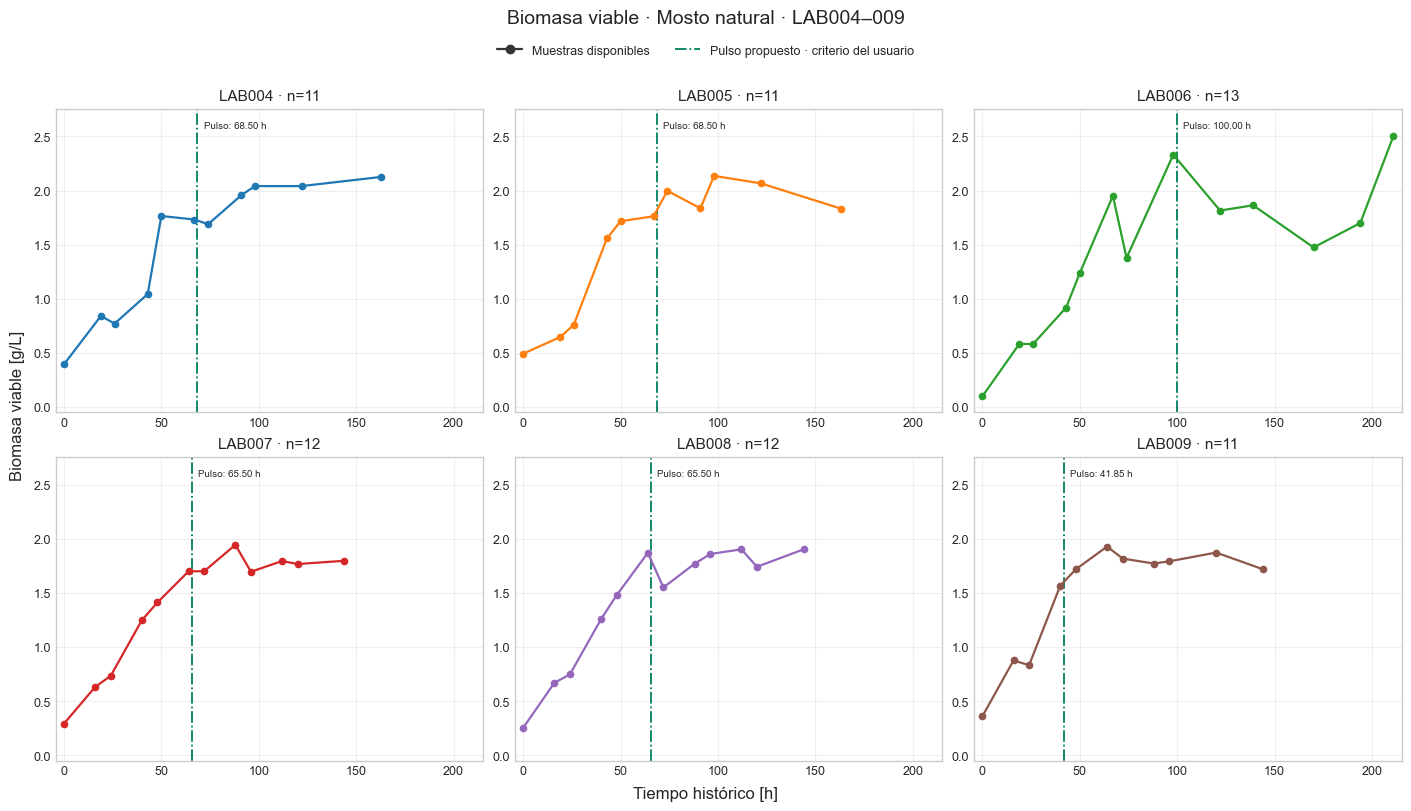

In [3]:
plot_matrix('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]', 'natural')

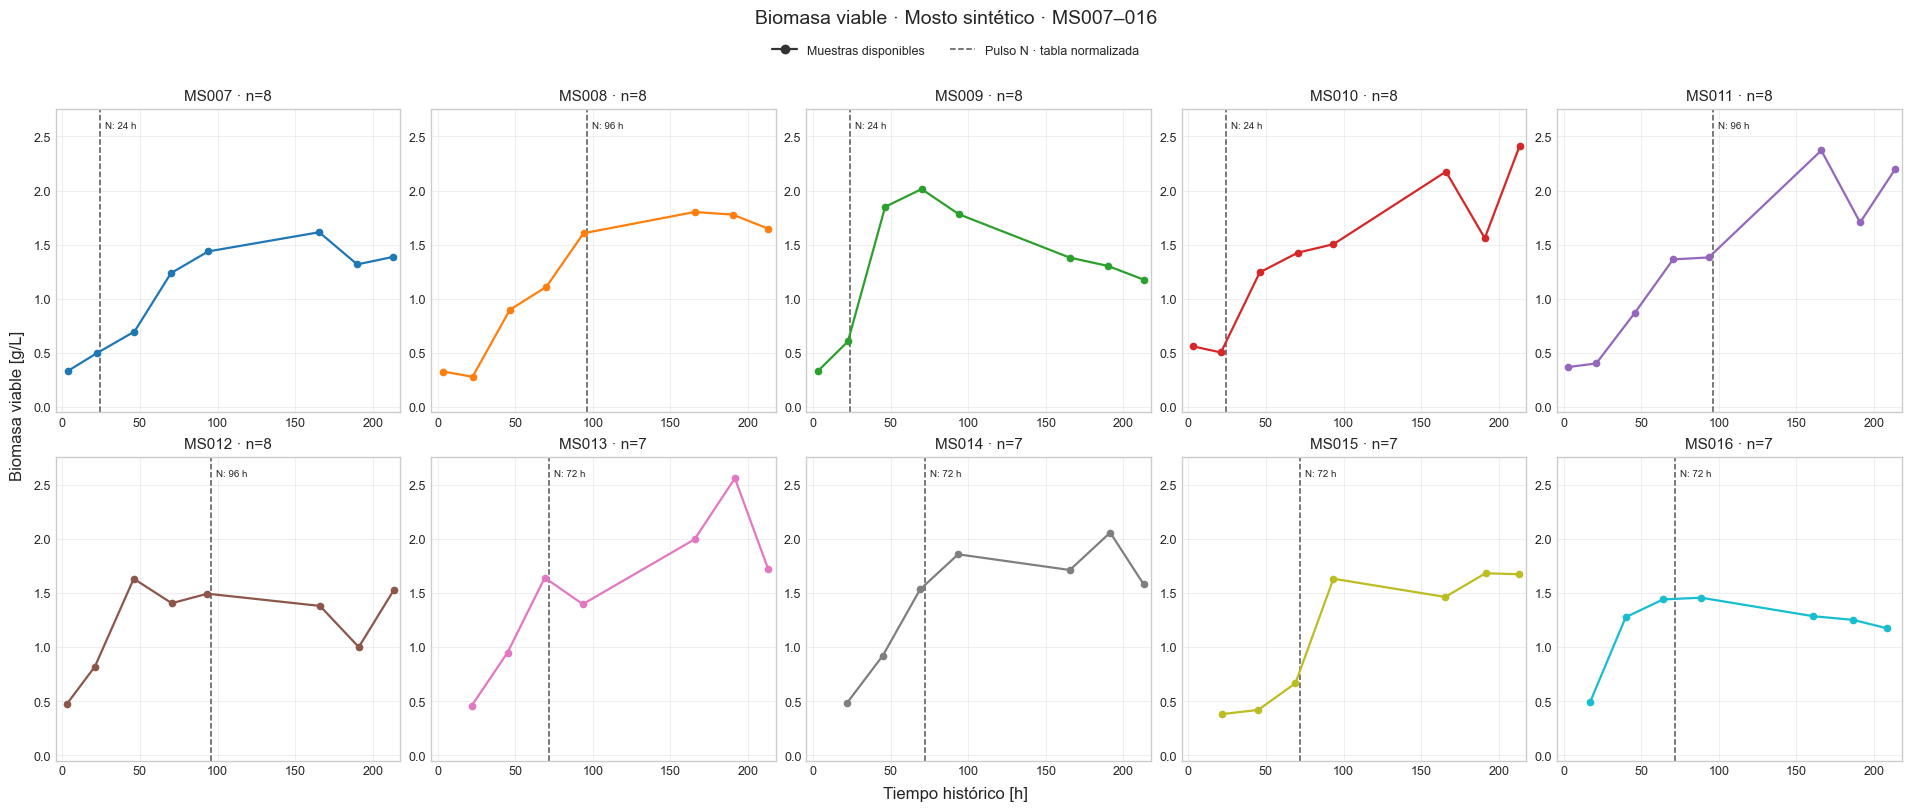

In [4]:
plot_matrix('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]', 'synthetic')

## 2. Nitrógeno asimilable (YAN)

Se muestran concentraciones medidas; las dosis de los pulsos no se dibujan como mediciones de YAN. Primero mosto natural; después mosto sintético.

En **YAN natural** se comparan calendario (gris discontinuo), cruce de densidad 1040 (magenta punteado) y pulso propuesto por el usuario (verde de trazo y punto). LAB004/005: muestra de 67 h + 1.5 h = 68.5 h; LAB006: muestra de 98 h + 2 h = 100 h; LAB007/008: muestra de 64 h + 1.5 h = 65.5 h; LAB009: cruce 1040 sin cambios. Se ha sumado una hora a la propuesta anterior de LAB004–008. Las anclas y siguientes muestras se comprueban contra el CSV y se documentan con fecha/hora local.

Los decimales no representan precisión experimental. Los horarios verdes son supuestos explícitos, no registros históricos confirmados; en LAB009 verde y magenta coinciden. Las otras figuras naturales usan el horario propuesto; las sintéticas mantienen las entradas archivadas. No se cambian datos, dosis ni calibraciones.


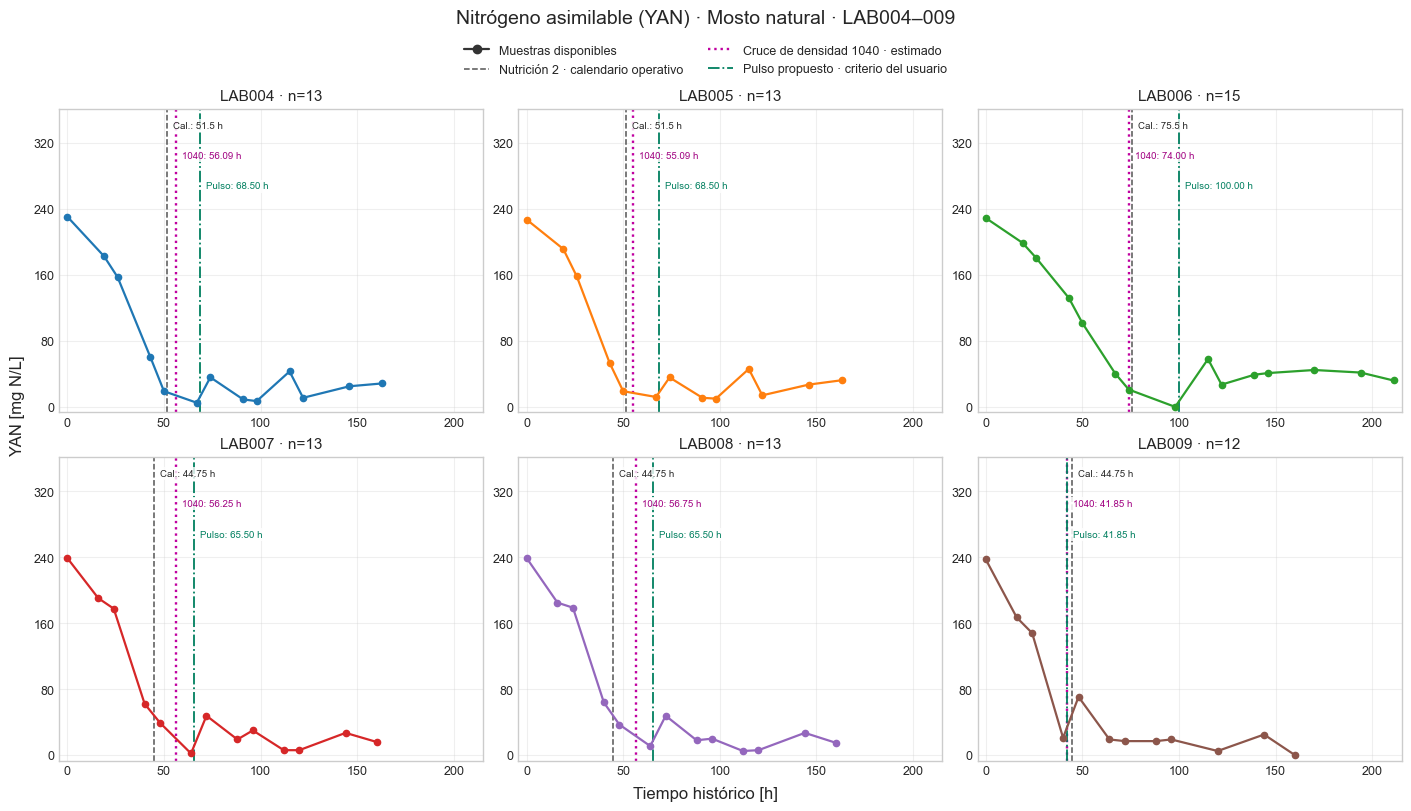

In [5]:
plot_matrix('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]', 'natural')

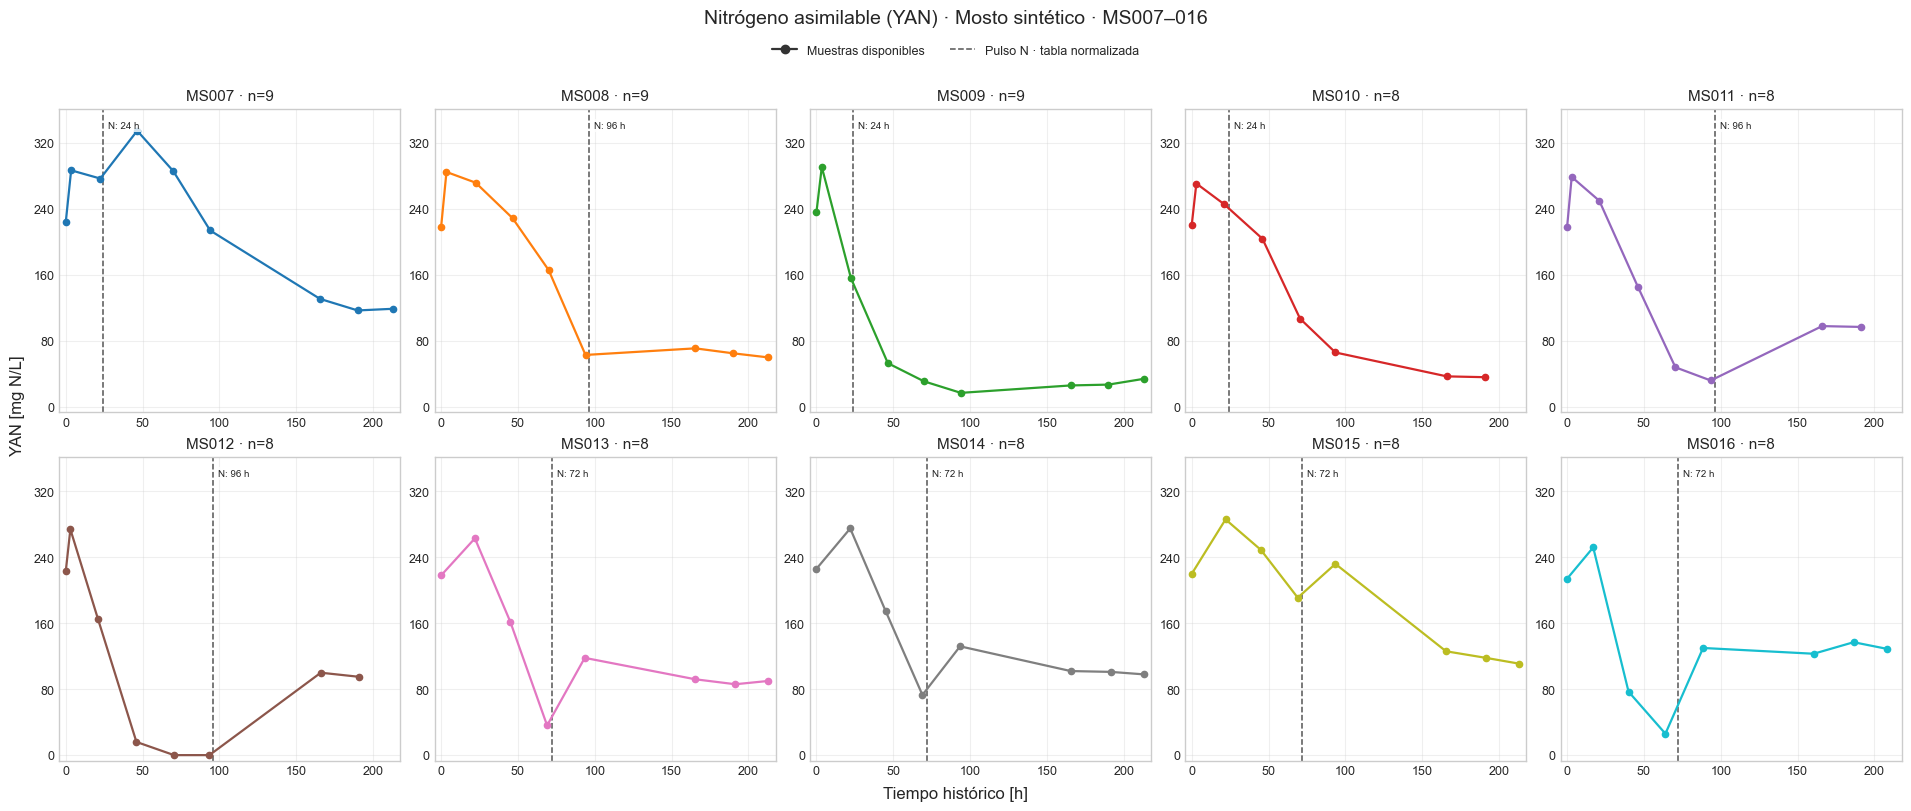

In [6]:
plot_matrix('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]', 'synthetic')

## 3. Glucosa



Primero mosto natural; después mosto sintético.

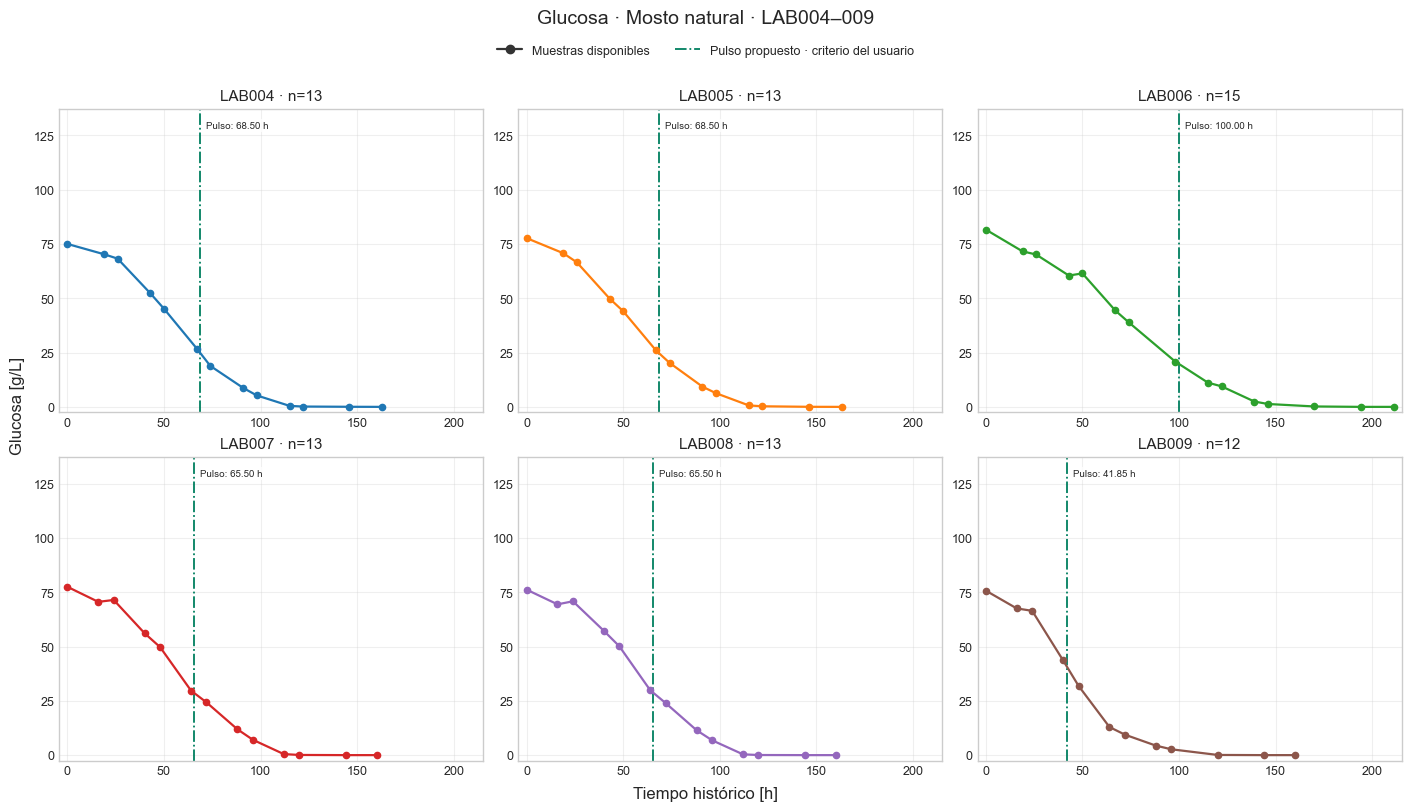

In [7]:
plot_matrix('G_g_l', 'Glucosa', 'Glucosa [g/L]', 'natural')

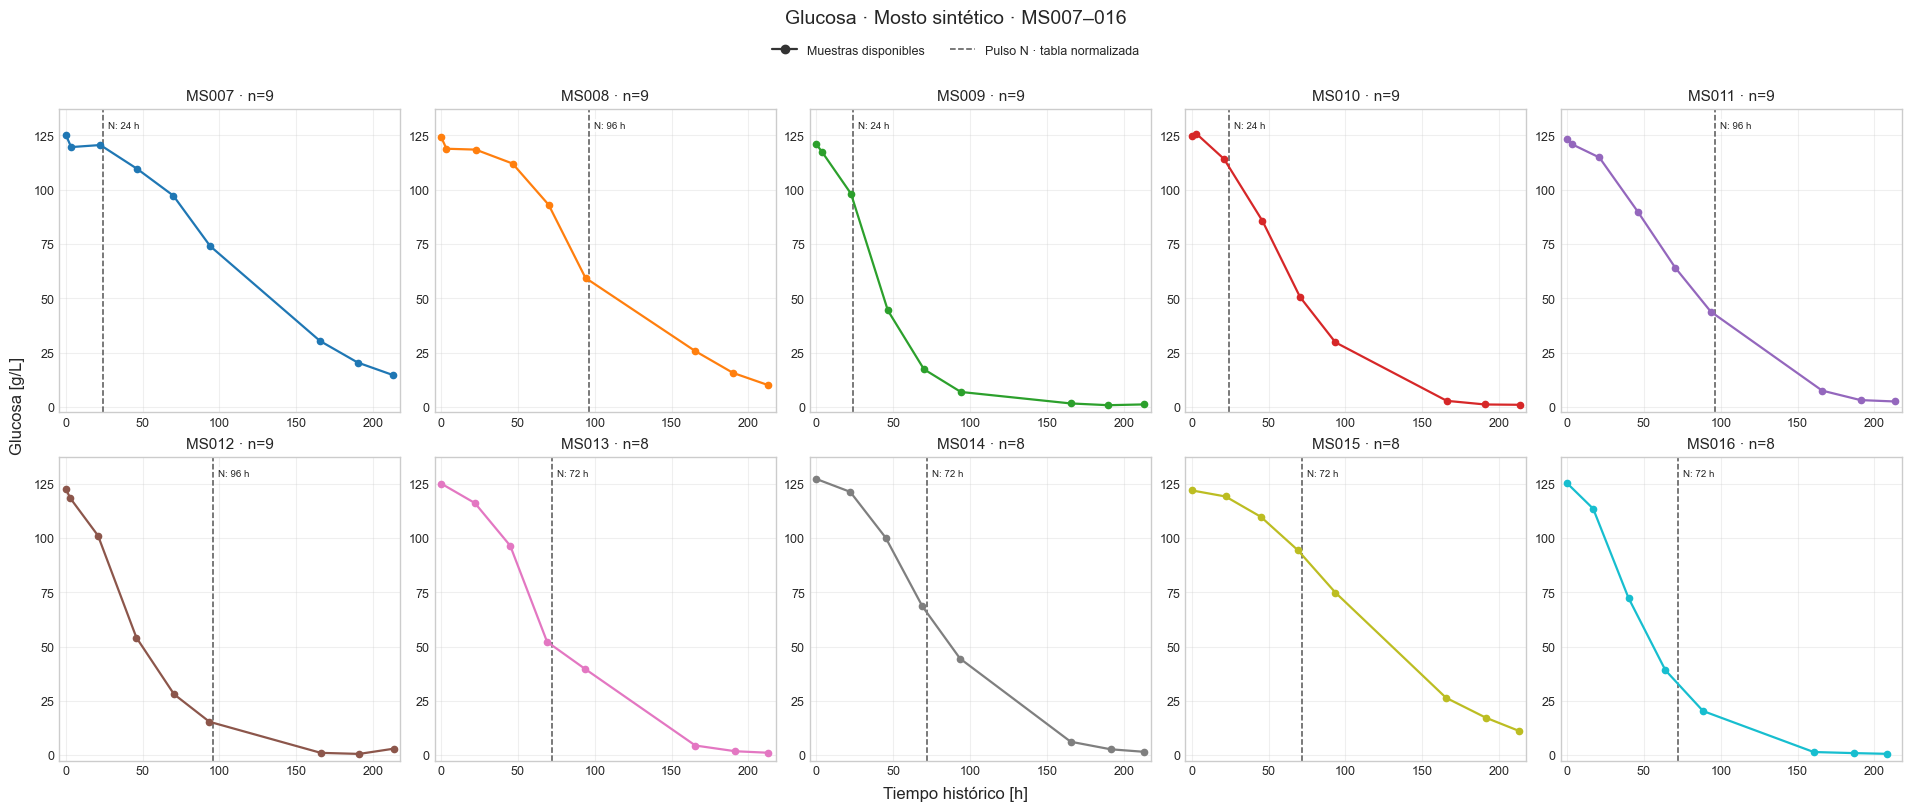

In [8]:
plot_matrix('G_g_l', 'Glucosa', 'Glucosa [g/L]', 'synthetic')

## 4. Fructosa



Primero mosto natural; después mosto sintético.

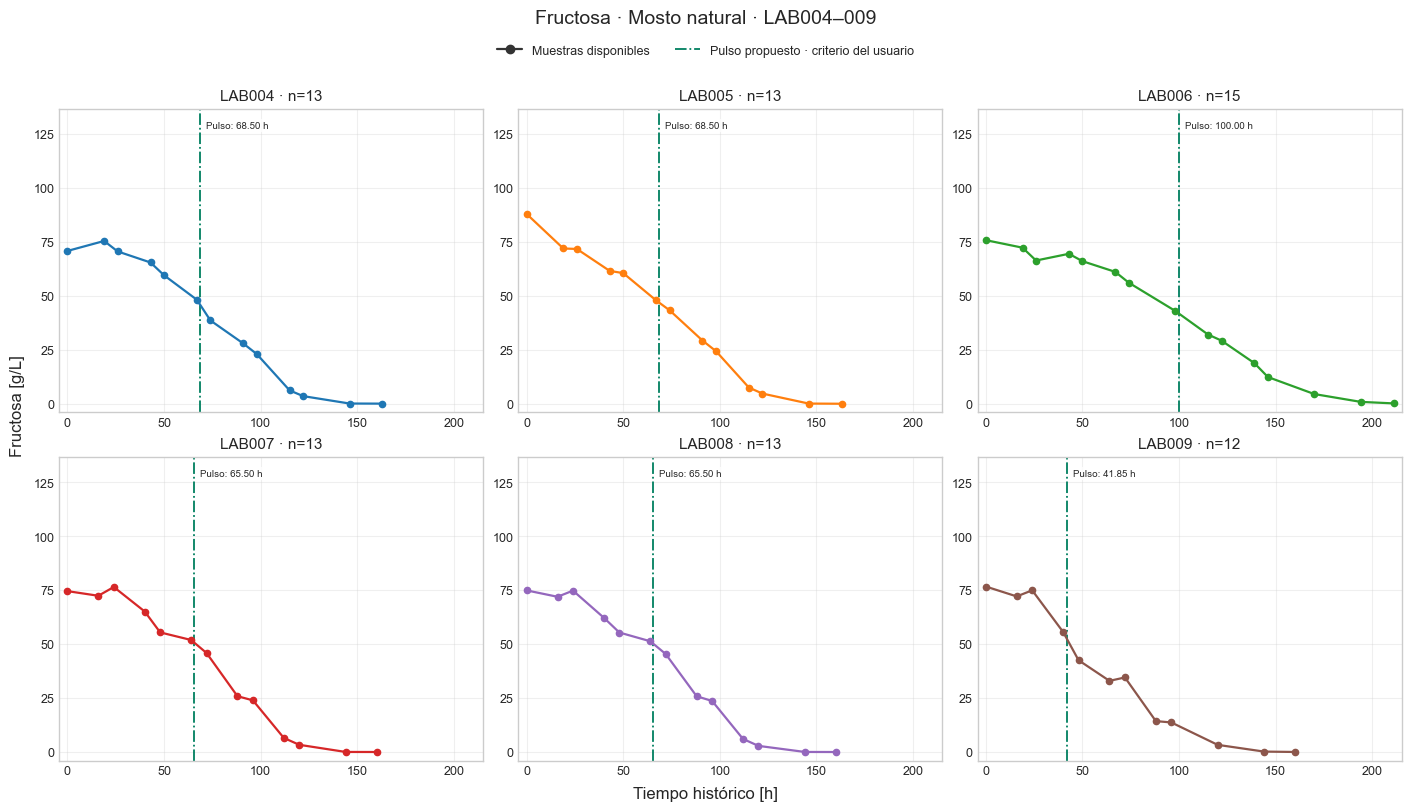

In [9]:
plot_matrix('F_g_l', 'Fructosa', 'Fructosa [g/L]', 'natural')

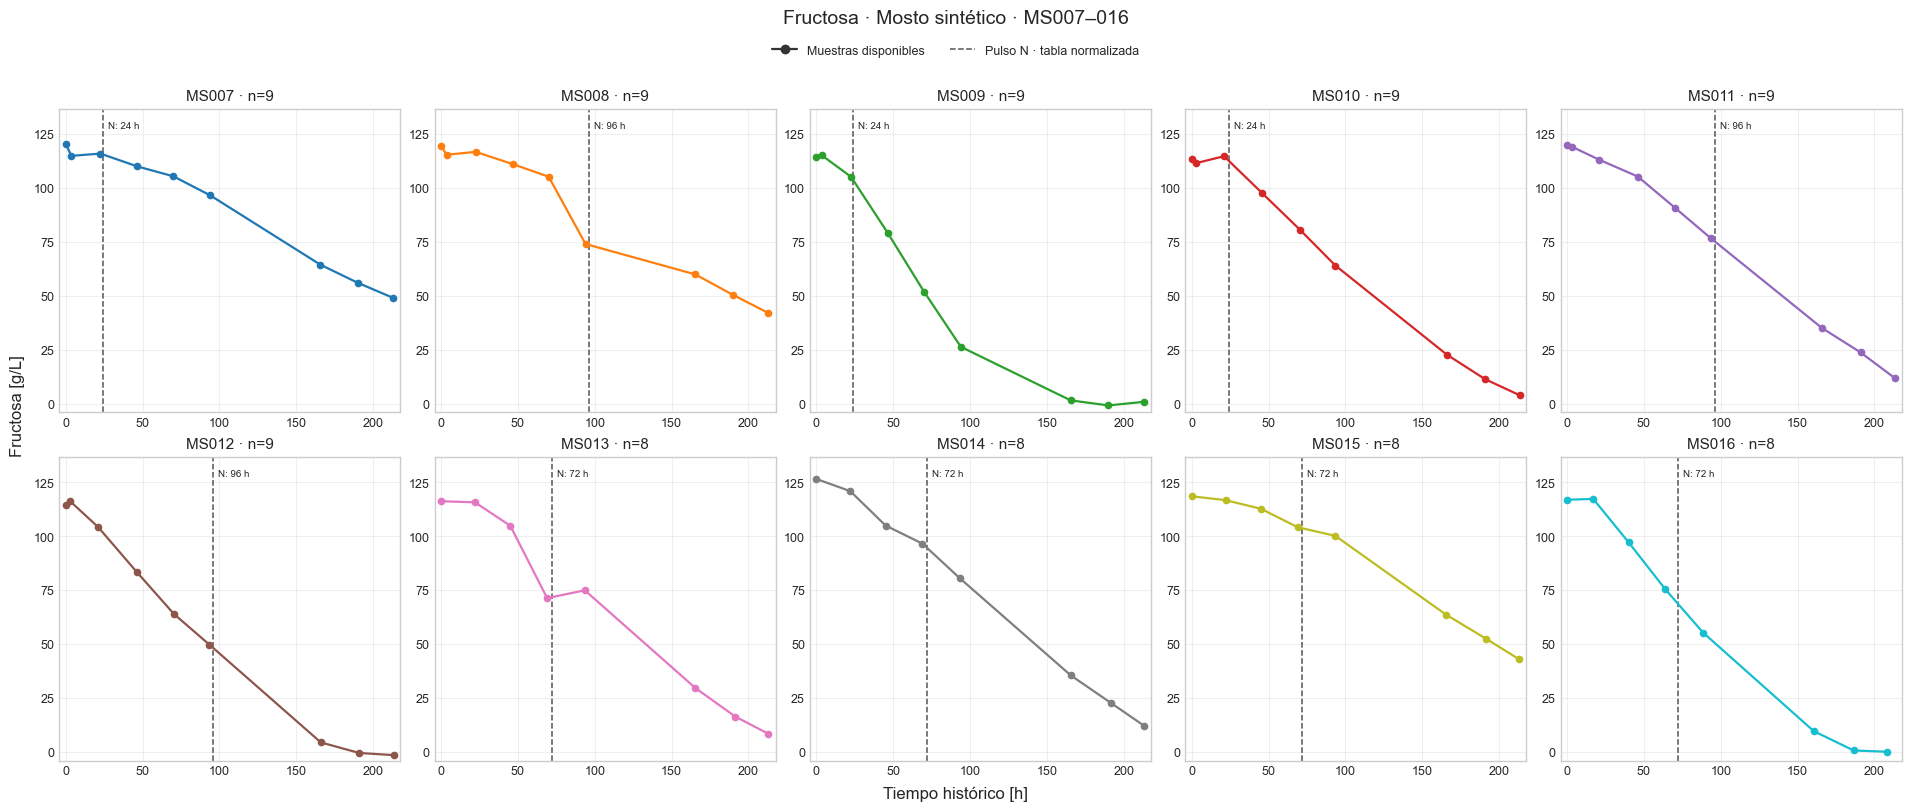

In [10]:
plot_matrix('F_g_l', 'Fructosa', 'Fructosa [g/L]', 'synthetic')

## 5. Azúcar total: glucosa + fructosa

La suma G+F usa únicamente pares medidos en la misma muestra. No se infiere azúcar desde densidad.

Primero mosto natural; después mosto sintético.

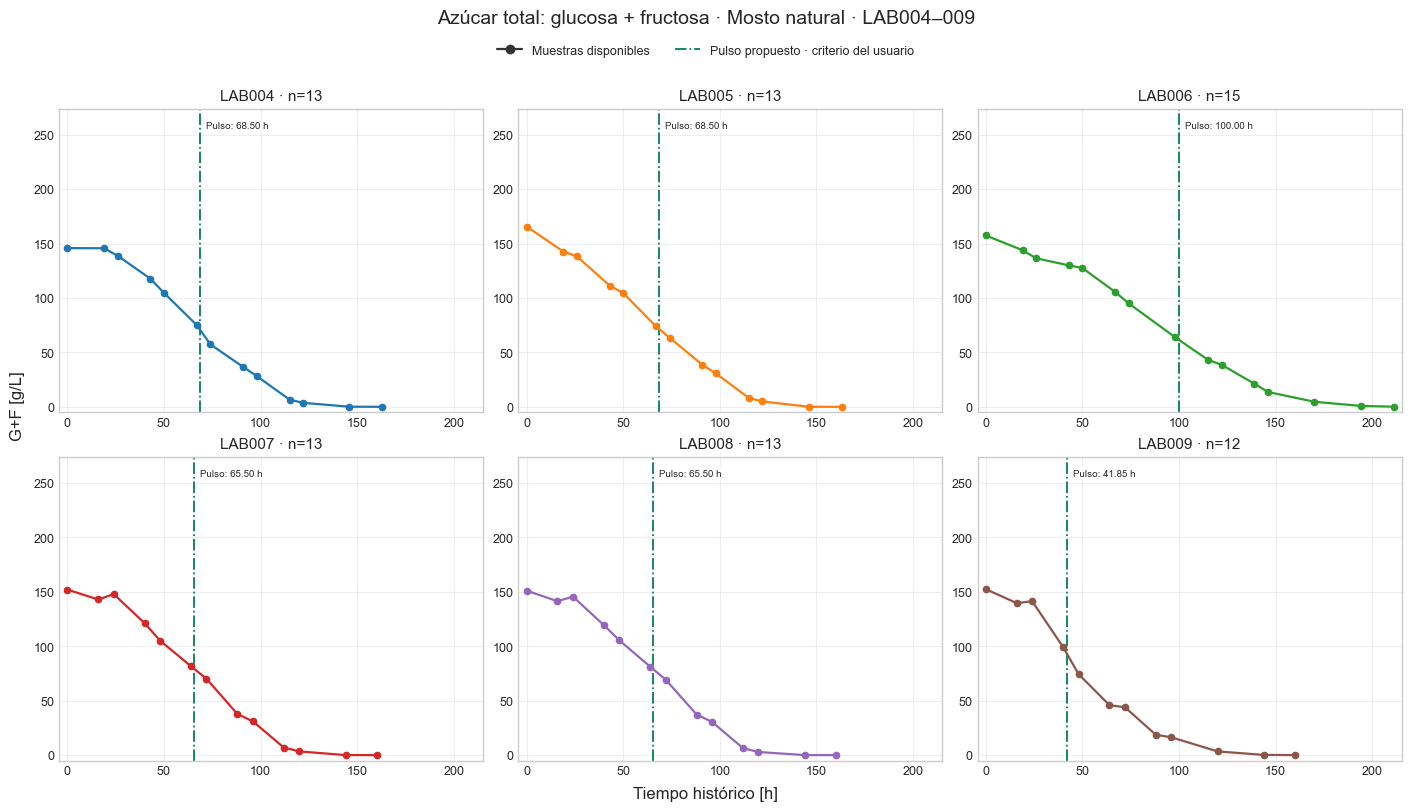

In [11]:
plot_matrix('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]', 'natural')

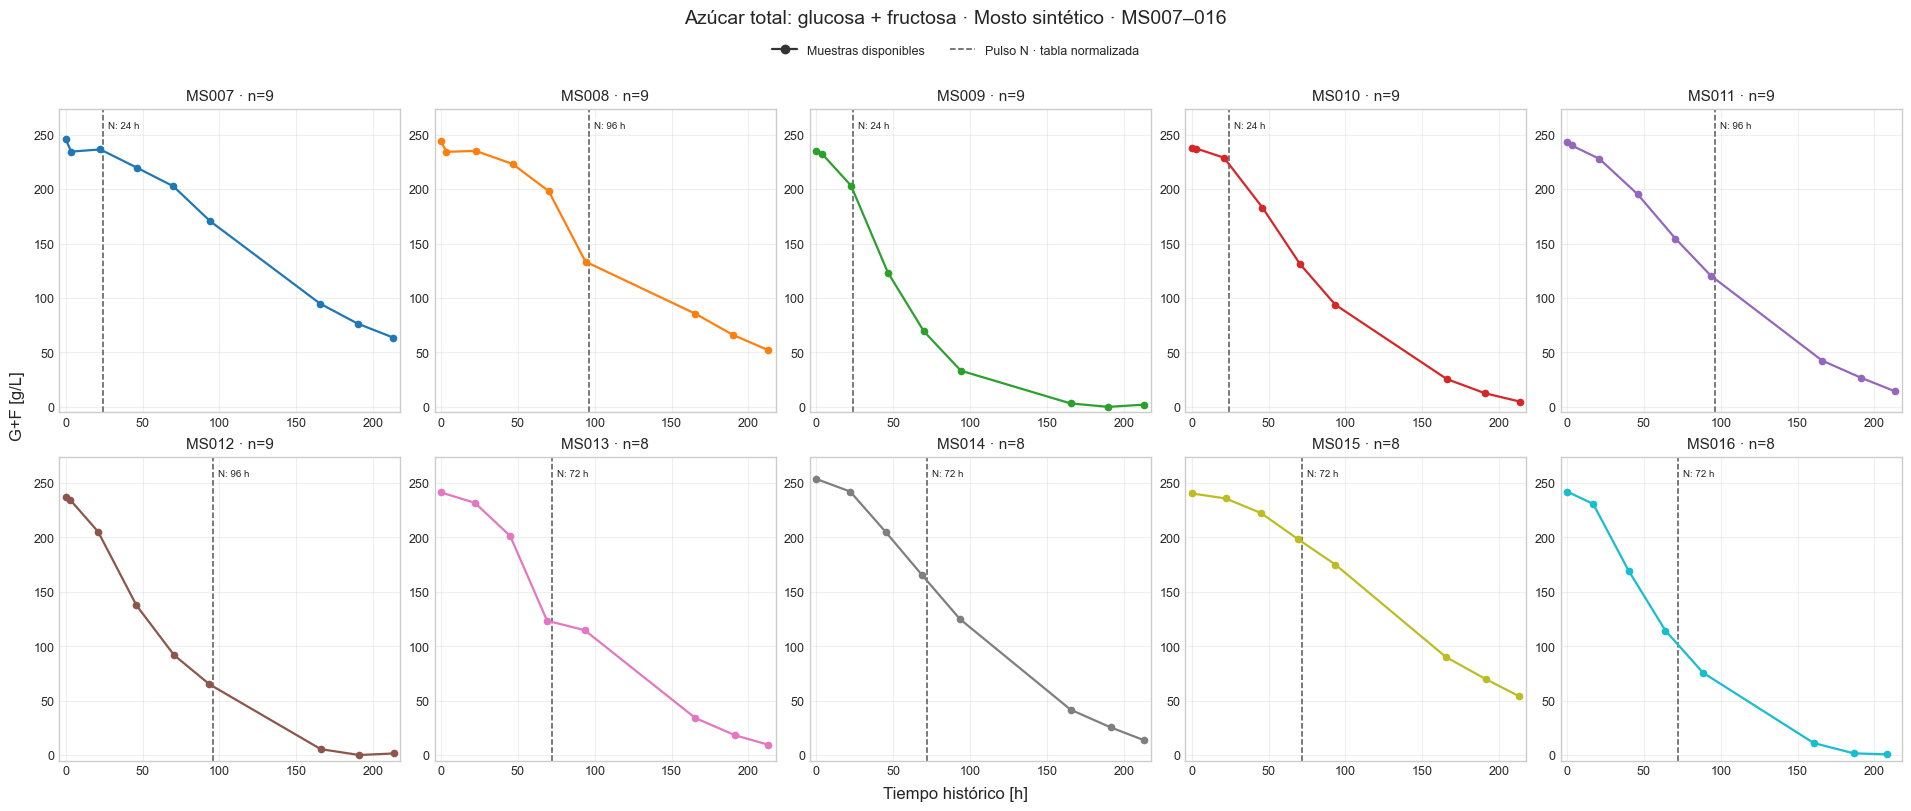

In [12]:
plot_matrix('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]', 'synthetic')

## 6. Densidad



Primero mosto natural; después mosto sintético.

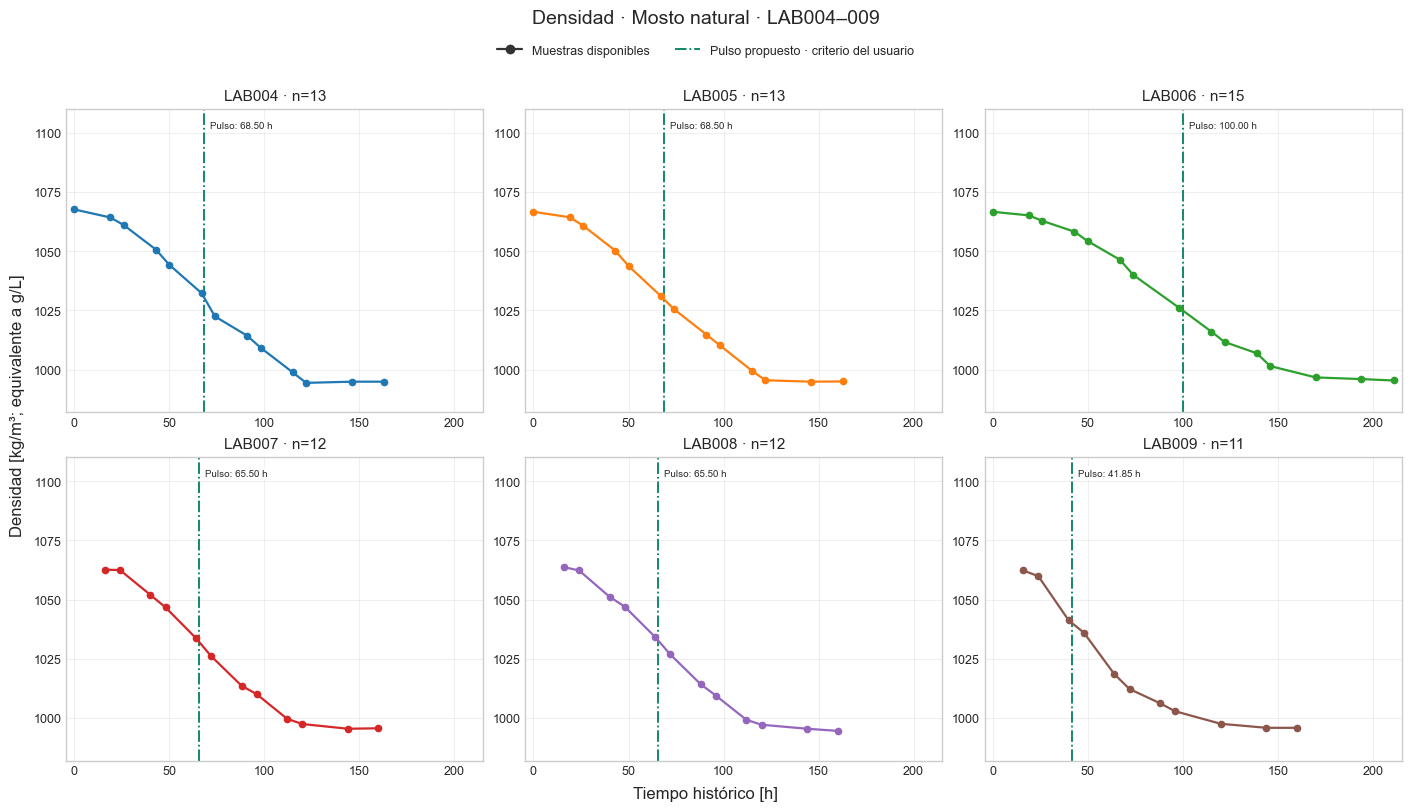

In [13]:
plot_matrix('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]', 'natural')

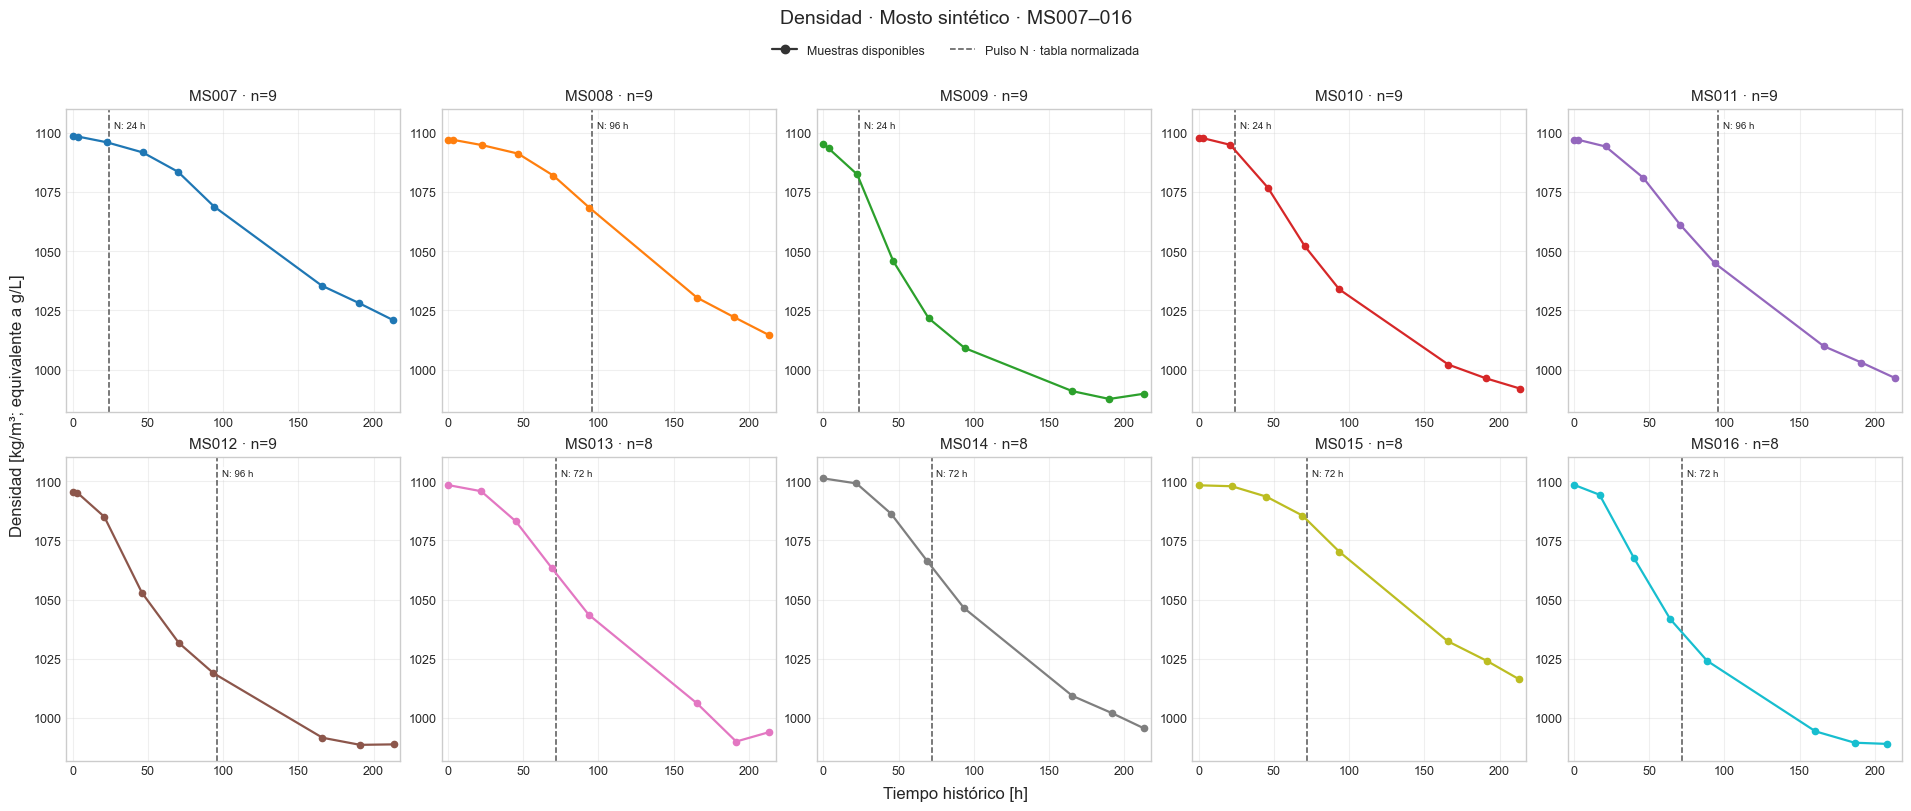

In [14]:
plot_matrix('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]', 'synthetic')

## 7. Etanol

Se usa E_g_l, la concentración de etanol normalizada que consume el modelo. Los sintéticos tienen cuatro puntos por experimento; las líneas solo unen esas mediciones.

Primero mosto natural; después mosto sintético.

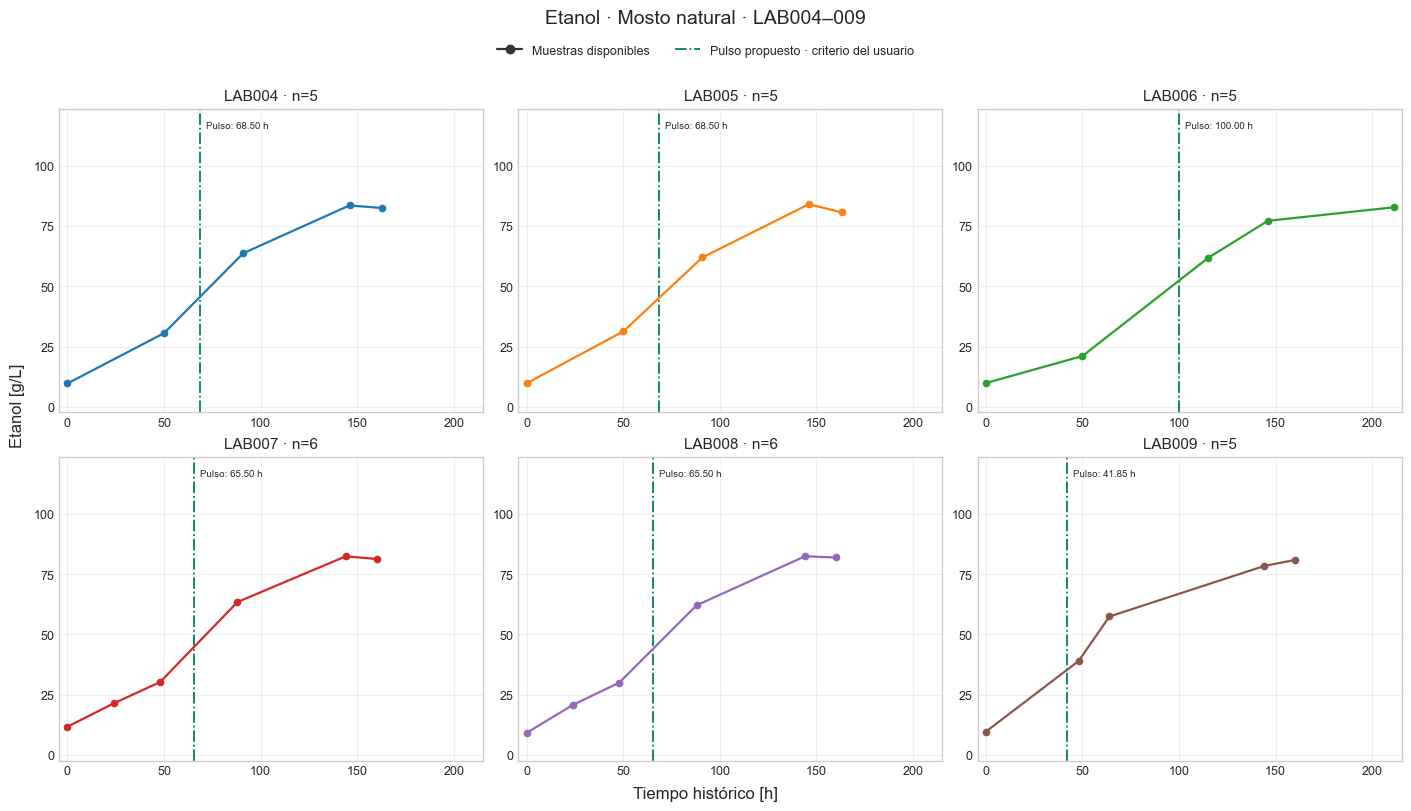

In [15]:
plot_matrix('E_g_l', 'Etanol', 'Etanol [g/L]', 'natural')

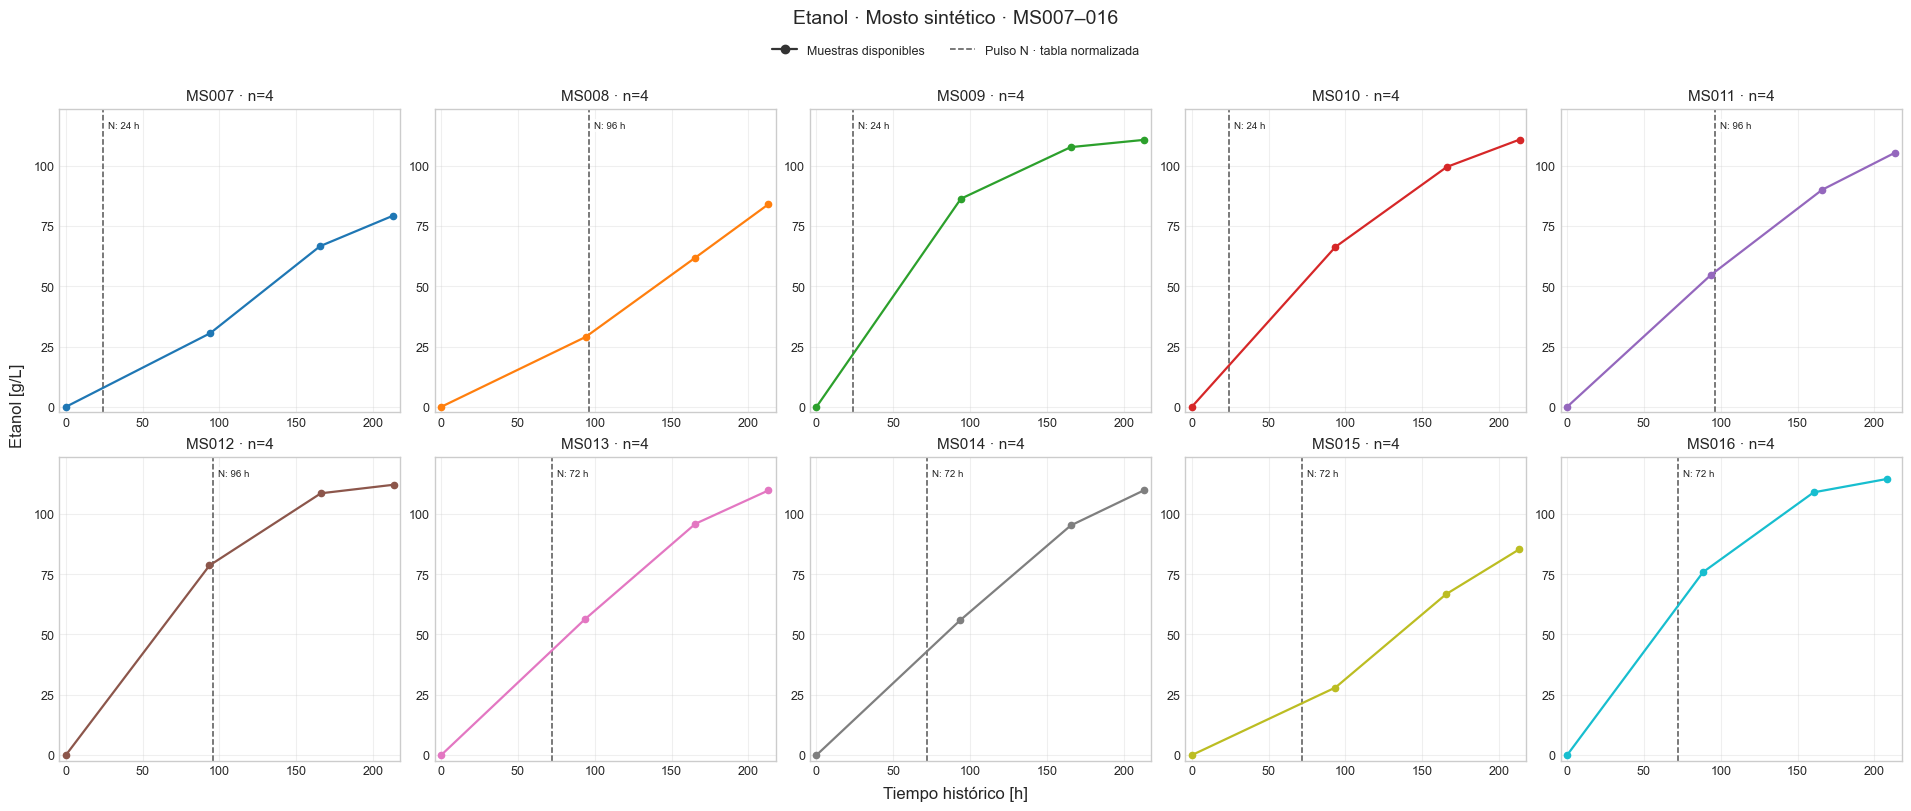

In [16]:
plot_matrix('E_g_l', 'Etanol', 'Etanol [g/L]', 'synthetic')

## 8. Temperatura y activaciones de bomba

Se conserva la selección **LAB004–009** y **MS007–016**; LAB010–012 no se incluyen.

**Referencia del filtro.** `chemistry_lab004_012_theta_comparison` muestra el sensor archivado con medianas de 30 minutos y su representación en la malla del modelo; no aplica Butterworth ni un filtro adicional. Aquí se reconstruyen los logs crudos naturales, se calculan las mismas medianas de 30 minutos y se suavizan más: mediana móvil centrada de tres intervalos (90 minutos), seguida de Butterworth de orden 2, período de corte de 4 h, aplicado hacia delante y atrás (sin desfase). Es una preparación visual, no una nueva temperatura de calibración.

Se filtra por tramos: no se atraviesan intervalos de 30 min sin datos ni cambios registrados de setpoint mayores de 0.5 °C. Los tramos demasiado cortos conservan la mediana móvil y se identifican en la auditoría. No se excluyen ventanas alrededor de la nutrición. Los vacíos de registro permanecen visibles.

Se incluye cada log desde el tiempo histórico cero hasta su última lectura disponible, aunque supere la última muestra química.

Las marcas rosadas al pie representan **todos los episodios registrados de `nutricion_activa = 1`** en el intervalo mostrado, sin imponer una duración mínima. Las muestras consecutivas activas forman un episodio; se corta también ante una separación de más de 30 s. Los extremos representan primera y última lectura activa, no tiempos exactos de accionamiento. No se confunden estos registros con dosis de N: la señal representa la orden de bomba de la GUI, sin identificar líquido ni cantidad. La línea verde mantiene el pulso provisional acordado, para comparación.

**Sintéticos:** no se encontraron logs continuos de temperatura/bomba de MS007–016 en los datos del repositorio. Se muestra aparte la columna `Temperatura Medida` del Excel, con la temperatura operacional como referencia. Son muestras espaciadas, no logs: no se aplica el filtro temporal diseñado para señales densas ni se inventan activaciones. El pulso de su tabla se conserva como supuesto archivado, no como evento confirmado por una bomba.


In [17]:
from scipy.signal import butter, sosfiltfilt
FM = ROOT / 'fermentation_model'
LOG_ROOT = FM / 'data/Laboratorio 2026/raw_data'
SYNTHETIC_BOOK = FM / 'data/Laboratorio 2025/mosto_sintetico_vl3.xlsx'
TEMP_FILTER = {'median_bin_min':30, 'rolling_bins':3, 'cutoff_period_h':4., 'order':2,
               'max_gap_h':.500001, 'pump_gap_s':30.}
temperature_input_hashes = {SYNTHETIC_BOOK:hashlib.sha256(SYNTHETIC_BOOK.read_bytes()).hexdigest()}
natural_temperature = {}
pump_episodes = {}
temperature_audit_rows = []
log_inventory_rows = []
filter_segments = []
for lab in LABS:
    paths = sorted(p for p in LOG_ROOT.rglob('*.csv')
                   if p.name.lower().startswith('temp')
                   and re.search(rf'lab0*{int(lab[3:])}(?:\D|$)', p.name, re.IGNORECASE))
    assert paths, f'Sin logs: {lab}'
    fragments = []
    for path in paths:
        temperature_input_hashes[path] = hashlib.sha256(path.read_bytes()).hexdigest()
        part = pd.read_csv(path, usecols=lambda c:c in ('timestamp','T','SP','nutricion_activa','freq_nut'))
        assert {'timestamp','T','SP','nutricion_activa'}.issubset(part.columns)
        part['timestamp'] = pd.to_datetime(part.timestamp, errors='coerce')
        for col in ['T','SP','nutricion_activa','freq_nut']:
            part[col] = pd.to_numeric(part[col], errors='coerce')
        part = part.dropna(subset=['timestamp'])
        log_inventory_rows.append({'LAB':lab,'archivo':str(path.relative_to(ROOT)),
            'n_registros':len(part),'inicio':part.timestamp.min(),'fin':part.timestamp.max()})
        fragments.append(part)
    records = pd.concat(fragments,ignore_index=True).sort_values('timestamp',kind='stable')
    # Las copias coincidentes deben coincidir en señal y estado, sin escoger una arbitrariamente.
    duplicated = records[records.timestamp.duplicated(keep=False)]
    if len(duplicated):
        assert duplicated.groupby('timestamp')[['T','SP','nutricion_activa']].nunique().le(1).all().all()
    records = records.drop_duplicates('timestamp').reset_index(drop=True)
    t0 = pd.Timestamp(clocks.loc[lab,'t0'])
    horizon = float(selected.loc[selected.batch.eq(lab),'time_h'].max())
    records['t_h'] = (records.timestamp-t0).dt.total_seconds()/3600.
    records = records[records.t_h.ge(0)].copy()
    horizon = float(records.t_h.max())
    assert len(records)
    # Episodios desde el log denso, antes de cualquier resumen de temperatura.
    starts=[]; ends=[]; samples=[]; current=[]; previous=None
    for row in records.itertuples(index=False):
        active = pd.notna(row.nutricion_activa) and row.nutricion_activa==1
        if current and (not active or (row.timestamp-previous).total_seconds()>TEMP_FILTER['pump_gap_s']):
            starts.append(current[0]); ends.append(current[-1]); samples.append(len(current)); current=[]
        if active:
            current.append(row.timestamp)
        previous=row.timestamp
    if current:
        starts.append(current[0]); ends.append(current[-1]); samples.append(len(current))
    events = pd.DataFrame({'inicio':starts,'fin':ends,'n_lecturas':samples})
    events['inicio_h'] = (pd.to_datetime(events.inicio)-t0).dt.total_seconds()/3600.
    events['fin_h'] = (pd.to_datetime(events.fin)-t0).dt.total_seconds()/3600.
    events['LAB']=lab
    pump_episodes[lab]=events
    assert sum(samples)==int(records.nutricion_activa.eq(1).sum())
    valid = records.dropna(subset=['T']).set_index('timestamp')
    sensor = valid[['T','SP']].resample('30min').median().dropna(subset=['T']).reset_index()
    sensor['t_h']=(sensor.timestamp-t0).dt.total_seconds()/3600.
    # La mediana se fecha en el centro de cada intervalo de 30 min (resumen offline).
    sensor['t_h'] += .25
    sensor = sensor[sensor.t_h.between(0,horizon)].copy()
    split = sensor.t_h.diff().gt(TEMP_FILTER['max_gap_h']) | sensor.SP.diff().abs().gt(.5)
    sensor['segment']=split.cumsum()
    sensor['filtrada']=np.nan
    sos=butter(TEMP_FILTER['order'],1/TEMP_FILTER['cutoff_period_h'],fs=2.,output='sos')
    for segment, group in sensor.groupby('segment'):
        values=group['T']
        smooth=values.rolling(TEMP_FILTER['rolling_bins'],center=True,min_periods=1).median().to_numpy()
        filtered=sosfiltfilt(sos,smooth) if len(smooth)>9 else smooth.copy()
        sensor.loc[group.index,'filtrada']=filtered
        filter_segments.append({'LAB':lab,'tramo':int(segment),'n_intervalos':len(group),
            'inicio_h':group.t_h.min(),'fin_h':group.t_h.max(),'butterworth_aplicado':len(smooth)>9})
    assert np.isfinite(sensor.filtrada).all()
    natural_temperature[lab]=sensor
    temperature_audit_rows.append({'LAB':lab,'n_archivos':len(paths),'n_lecturas_T':int(records['T'].notna().sum()),
        'inicio_log_h':records.t_h.min(),'fin_log_h':records.t_h.max(),'n_activaciones':len(events),
        'n_lecturas_bomba_activa':sum(samples),'pulso_propuesto_h':proposed_times[lab]})
log_inventory=pd.DataFrame(log_inventory_rows)
temperature_audit=pd.DataFrame(temperature_audit_rows)
filter_segment_audit=pd.DataFrame(filter_segments)
display(temperature_audit.round(3))
display(log_inventory)
display(filter_segment_audit.groupby('LAB').agg(tramos=('tramo','size'),
    tramos_con_butterworth=('butterworth_aplicado','sum')))
# Tabla detallada inline; no exporta CSV ni altera las tablas químicas.
all_pump_episodes=pd.concat(pump_episodes.values(),ignore_index=True)
with pd.option_context('display.max_rows',20):
    display(all_pump_episodes)

,LAB,n_archivos,n_lecturas_T,inicio_log_h,fin_log_h,n_activaciones,n_lecturas_bomba_activa,pulso_propuesto_h
0,LAB004,2,196727,1.770,190.661,116,845,68.500
1,LAB005,2,196715,1.782,190.674,62,576,68.500
2,LAB006,2,220395,1.790,213.665,2,3,100.000
3,LAB007,1,143525,0.001,161.625,149,710,65.500
4,LAB008,1,143527,0.000,161.626,69,458,65.500
5,LAB009,1,143528,0.000,161.628,1,1,41.846


,LAB,archivo,n_registros,inicio,fin
0,LAB004,fermentation_model\data\Laboratorio 2026\raw_d...,17346,2026-04-06 14:46:13,2026-04-07 07:13:27
1,LAB004,fermentation_model\data\Laboratorio 2026\raw_d...,179381,2026-04-07 08:20:22,2026-04-14 11:39:40
2,LAB005,fermentation_model\data\Laboratorio 2026\raw_d...,17333,2026-04-06 14:46:55,2026-04-07 07:13:24
3,LAB005,fermentation_model\data\Laboratorio 2026\raw_d...,179382,2026-04-07 08:21:03,2026-04-14 11:40:25
4,LAB006,fermentation_model\data\Laboratorio 2026\raw_d...,17325,2026-04-06 14:47:23,2026-04-07 07:13:25
5,LAB006,fermentation_model\data\Laboratorio 2026\raw_d...,203070,2026-04-07 08:21:28,2026-04-15 10:39:55
6,LAB007,fermentation_model\data\Laboratorio 2026\raw_d...,148435,2026-04-17 11:20:36,2026-04-24 09:37:30
7,LAB008,fermentation_model\data\Laboratorio 2026\raw_d...,148426,2026-04-17 11:21:11,2026-04-24 09:37:35
8,LAB009,fermentation_model\data\Laboratorio 2026\raw_d...,148421,2026-04-17 11:21:32,2026-04-24 09:37:39


,tramos,tramos_con_butterworth
LAB,,
LAB004,4,4
LAB005,4,4
LAB006,3,3
LAB007,2,2
LAB008,2,2
LAB009,2,2


,inicio,fin,n_lecturas,inicio_h,fin_h,LAB
0,2026-04-06 14:46:13,2026-04-06 14:46:23,4,1.770278,1.773056,LAB004
1,2026-04-06 14:51:13,2026-04-06 14:51:24,4,1.853611,1.856667,LAB004
2,2026-04-06 14:51:37,2026-04-06 14:51:58,7,1.860278,1.866111,LAB004
3,2026-04-07 08:55:14,2026-04-07 08:55:28,5,19.920556,19.924444,LAB004
4,2026-04-07 08:55:41,2026-04-07 08:55:51,4,19.928056,19.930833,LAB004
...,...,...,...,...,...,...
394,2026-04-24 09:02:23,2026-04-24 09:02:42,6,161.039722,161.045000,LAB008
395,2026-04-24 09:02:50,2026-04-24 09:02:54,2,161.047222,161.048333,LAB008
396,2026-04-24 09:19:52,2026-04-24 09:20:07,5,161.331111,161.335278,LAB008
397,2026-04-24 09:34:35,2026-04-24 09:34:39,2,161.576389,161.577500,LAB008


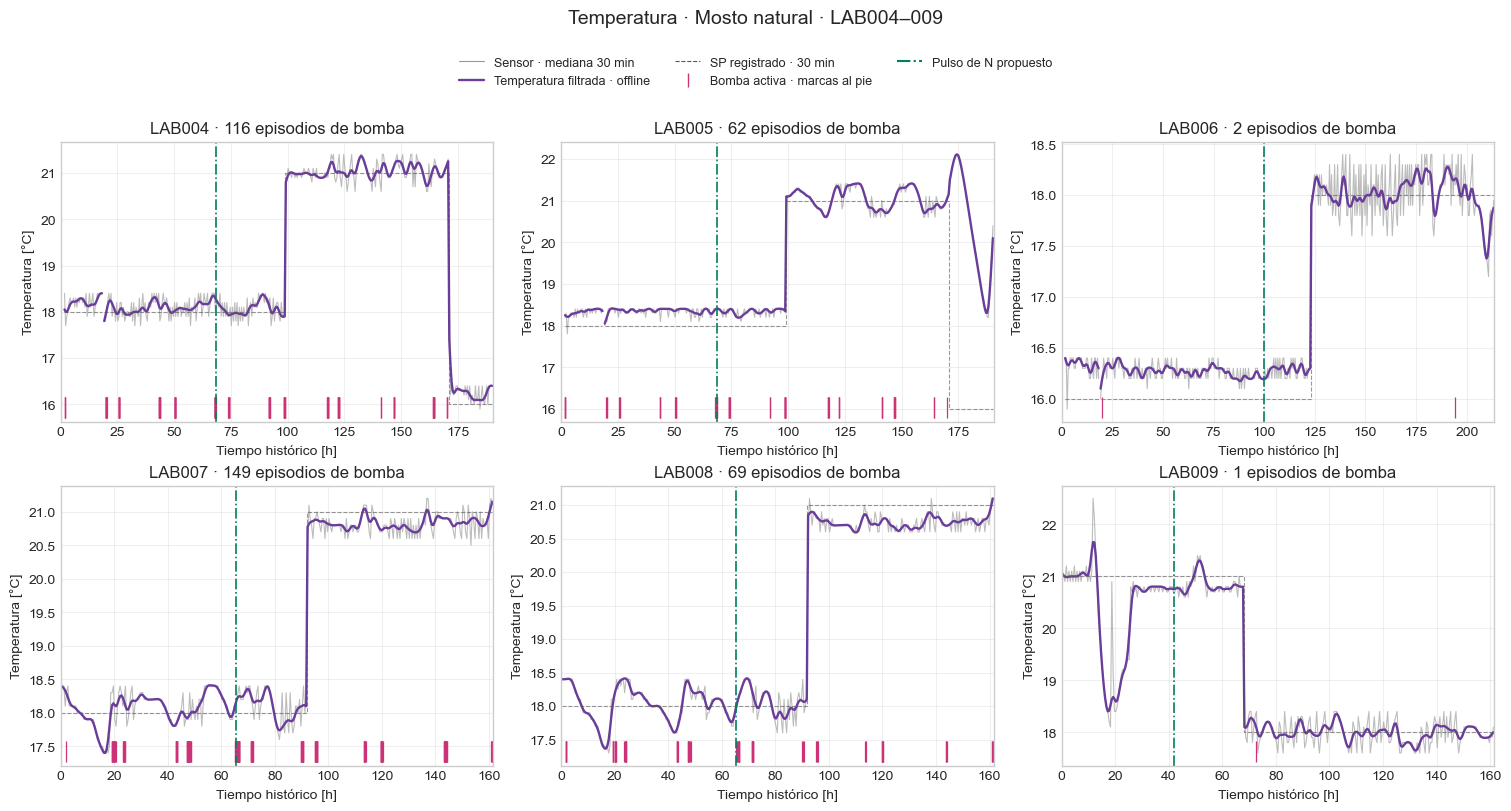

In [18]:
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    sensor=natural_temperature[lab]
    # Unir el salto térmico visible sin suavizarlo; romper solo los huecos reales.
    display_segments=sensor.t_h.diff().gt(TEMP_FILTER['max_gap_h']).cumsum()
    for segment,group in sensor.groupby(display_segments):
        ax.plot(group.t_h,group['T'],color='#999999',lw=.8,alpha=.65)
        ax.plot(group.t_h,group.filtrada,color='#6A3D9A',lw=1.7)
        ax.step(group.t_h,group.SP,where='mid',color='#555555',ls='--',lw=.8,alpha=.6)
    events=pump_episodes[lab]
    for event in events.itertuples():
        ax.plot([event.inicio_h,event.fin_h],[.045,.045],color='#CC3377',lw=3,
                solid_capstyle='butt',transform=ax.get_xaxis_transform())
        ax.vlines(event.inicio_h,.015,.09,color='#CC3377',lw=.9,transform=ax.get_xaxis_transform())
    ax.axvline(proposed_times[lab],color='#007F5F',ls='-.',lw=1.2)
    horizon=float(temperature_audit.set_index('LAB').loc[lab,'fin_log_h'])
    ax.set(title=f'{lab} · {len(events)} episodios de bomba',xlim=(0,horizon),
           xlabel='Tiempo histórico [h]',ylabel='Temperatura [°C]')
    ax.grid(alpha=.3)
handles=[Line2D([],[],color='#999999',lw=.8,label='Sensor · mediana 30 min'),
         Line2D([],[],color='#6A3D9A',lw=1.7,label='Temperatura filtrada · offline'),
         Line2D([],[],color='#555555',ls='--',lw=.8,label='SP registrado · 30 min'),
         Line2D([],[],color='#CC3377',marker='|',ls='none',markersize=10,label='Bomba activa · marcas al pie'),
         Line2D([],[],color='#007F5F',ls='-.',label='Pulso de N propuesto')]
fig.suptitle('Temperatura · Mosto natural · LAB004–009',y=.995,fontsize=14)
fig.get_layout_engine().set(rect=(0,0,1,.86))
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.95),ncol=3,frameon=False,fontsize=9)
plt.show(); plt.close(fig)

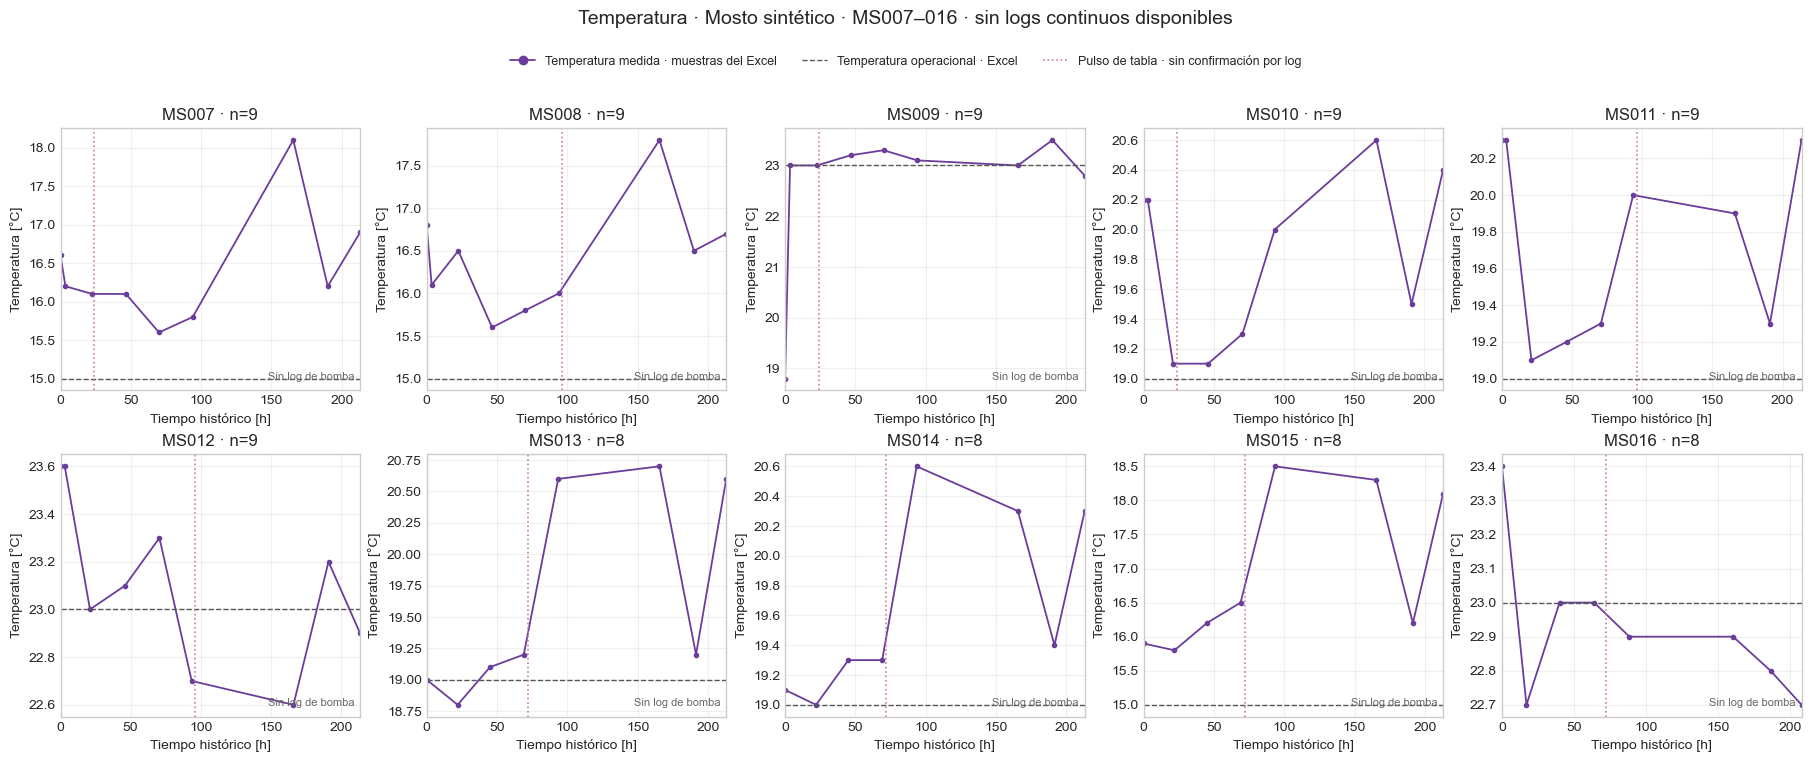

,MS,muestras_T_medida,log_continuo_disponible,activaciones_bomba_disponibles
0,MS007,9,False,False
1,MS008,9,False,False
2,MS009,9,False,False
3,MS010,9,False,False
4,MS011,9,False,False
5,MS012,9,False,False
6,MS013,8,False,False
7,MS014,8,False,False
8,MS015,8,False,False
9,MS016,8,False,False


Verificado: 2 matrices de temperatura añadidas, 6 naturales + 10 sintéticos; fuentes intactas.


In [19]:
synthetic_temperature={}
for lab in SYNTHETIC_LABS:
    sheet=pd.read_excel(SYNTHETIC_BOOK,sheet_name=lab,usecols=['t','Temperatura Medida','temperatura'])
    for col in sheet.columns:
        sheet[col]=pd.to_numeric(sheet[col],errors='coerce')
    sheet=sheet.dropna(subset=['t']).sort_values('t')
    assert sheet['Temperatura Medida'].notna().sum()>=2
    synthetic_temperature[lab]=sheet
fig,axes=plt.subplots(2,5,figsize=(18,7.5),layout='constrained')
for ax,lab in zip(axes.flat,SYNTHETIC_LABS):
    sheet=synthetic_temperature[lab]
    measured=sheet.dropna(subset=['Temperatura Medida'])
    nominal=sheet.dropna(subset=['temperatura'])
    ax.plot(measured.t,measured['Temperatura Medida'],color='#6A3D9A',marker='o',ms=3,lw=1.3)
    ax.plot(nominal.t,nominal.temperatura,color='#555555',ls='--',lw=1)
    for pulse in synthetic_nutrition[synthetic_nutrition.batch.eq(lab)].itertuples():
        ax.axvline(pulse.time_h,color='#CC79A7',ls=':',lw=1.2)
    ax.set(title=f'{lab} · n={len(measured)}',xlabel='Tiempo histórico [h]',ylabel='Temperatura [°C]',
           xlim=(0,float(sheet.t.max())))
    ax.text(.98,.04,'Sin log de bomba',transform=ax.transAxes,ha='right',fontsize=8,color='#666666')
    ax.grid(alpha=.3)
handles=[Line2D([],[],color='#6A3D9A',marker='o',lw=1.3,label='Temperatura medida · muestras del Excel'),
         Line2D([],[],color='#555555',ls='--',lw=1,label='Temperatura operacional · Excel'),
         Line2D([],[],color='#CC79A7',ls=':',lw=1.2,label='Pulso de tabla · sin confirmación por log')]
fig.suptitle('Temperatura · Mosto sintético · MS007–016 · sin logs continuos disponibles',y=.995,fontsize=14)
fig.get_layout_engine().set(rect=(0,0,1,.87))
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.95),ncol=3,frameon=False,fontsize=9)
plt.show(); plt.close(fig)
display(pd.DataFrame([{'MS':lab,'muestras_T_medida':int(sheet['Temperatura Medida'].notna().sum()),
    'log_continuo_disponible':False,'activaciones_bomba_disponibles':False}
    for lab,sheet in synthetic_temperature.items()]))
assert set(natural_temperature)==set(LABS) and set(synthetic_temperature)==set(SYNTHETIC_LABS)
assert not any(lab in natural_temperature for lab in ['LAB010','LAB011','LAB012'])
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in temperature_input_hashes.items())
assert sum(temperature_audit.n_lecturas_bomba_activa)==int(all_pump_episodes.n_lecturas.sum())
print('Verificado: 2 matrices de temperatura añadidas, 6 naturales + 10 sintéticos; fuentes intactas.')

## Verificación y alcance

Esta vista reúne 16 experimentos y siete variables, sin ajustar parámetros ni modificar las fuentes. Los recuentos de cada panel se contrastan con la tabla de cobertura, y se comprueba que las escalas verticales coincidan entre matrices. Los faltantes permanecen ausentes. Las líneas entre muestras no permiten afirmar qué ocurrió dentro de los intervalos sin medición; esto es especialmente relevante para el etanol sintético. Glicerol y biomasa muerta no se muestran por el alcance solicitado, aunque el modelo actual todavía los contiene.

In [20]:
assert len(plot_audit) == 14
expected_order = [(column, medium) for column, _, _ in VARIABLES for medium in MATRICES]
assert [(row['variable'], row['medium']) for row in plot_audit] == expected_order
for i, (column, _, _) in enumerate(VARIABLES):
    natural, synthetic = plot_audit[2*i:2*i+2]
    assert natural['ylim'] == synthetic['ylim']
    for entry in (natural, synthetic):
        medium = entry['medium']
        assert entry['n_panels'] == len(MATRICES[medium])
        expected = selected.loc[selected.medium.eq(medium)].groupby('batch')[column].count().to_dict()
        assert entry['counts'] == expected
assert sum(plot_audit[0]['counts'].values()) == 70
assert all(n == 4 for n in plot_audit[-1]['counts'].values())
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == input_hash
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in nutrition_input_hashes.items())
print('Verificado: 16 experimentos, 7 variables, 14 figuras y 112 paneles; fuentes intactas.')

assert [row['variable'] for row in plot_audit if row['compares_density_1040']] == ['YAN_mg_l']
assert all(row['medium']=='natural' for row in plot_audit if row['compares_density_1040'])
assert len(density_crossings)==6 and abs(density_times['LAB006']-74.)<1e-9

assert [row['medium'] for row in plot_audit if row['uses_proposed_pulse']] == ['natural']*7
assert all(abs(proposed_times[lab]-value)<1e-9 for lab,value in
           {'LAB004':68.5,'LAB005':68.5,'LAB006':100.,'LAB007':65.5,'LAB008':65.5}.items())
assert abs(proposed_times['LAB009']-density_times['LAB009'])<1e-12


Verificado: 16 experimentos, 7 variables, 14 figuras y 112 paneles; fuentes intactas.
